# Forklift / Pallet Detection (YOLO11)

**Task.** Detect forklifts and pallets in warehouse images and video. Output: class, box and confidence for each object.

**Approach in one paragraph.** 2D object detection with a single-stage YOLO11 detector, fine-tuned from COCO weights. The main source is a Roboflow Universe warehouse dataset with five classes (`forklift`, `pallet`, `pallet_truck`, `small_load_carrier`, `stillage`). It has almost no forklift annotations, so a second Roboflow dataset that does label forklifts is merged in. Only `forklift` and `pallet` are needed, so everything is filtered into a clean two-class copy with a careful policy for images that contain only the removed classes. There is no usable test split, so one is carved from the pooled train data with near-duplicate frames kept together. The rare class (forklift) is repeated in training, and confident model predictions are added as labels where a source does not annotate a class. Model sizes are compared on validation, and the winner is reported once on the test set. A manual error analysis and an ONNX latency check close the loop.

## Notebook map

| Section | Content |
|---|---|
| 0. Setup | Install the libraries |
| 1. Config | Imports, seed, preset, paths, device |
| 2. Dataset preparation | Merge and filter the source datasets to forklift and pallet, verify and audit |
| 3. Split hygiene | Test split without near-duplicate leakage |
| 4. Exploratory analysis | Box counts, box sizes, sample images |
| 5. Training | Class-imbalance fix, YOLO11n / YOLO11s training, optional self-training |
| 6. Evaluation | Model selection, NMS tuning, final test metrics |
| 7. Error analysis | Operating threshold, confusion matrix, size and per-source errors |
| 8. Speed and ONNX export | CPU speed and ONNX model |
| 9. Download | Weights package |
| 10. Video and tracking | Optional |
| 11. Summary | Numbers for the report |

Each big step below has its own sub-heading, so the sections can be collapsed in Jupyter, VS Code and Kaggle.

## 0. Setup

Add the datasets to the notebook with **Add data**: the five-class warehouse dataset and a Roboflow forklift dataset (YOLOv8-format export; segmentation or box labels both work). Turn **Internet** on in the notebook settings (needed for pip and for downloading weights). Use a **GPU** accelerator.

In [1]:
!pip -q install ultralytics onnx onnxslim onnxruntime

## 1. Config

### 1.1 Imports and random seed

Libraries used by the whole notebook and the global random seed.

In [ ]:
import os, sys, re, gc, json, shutil, random, time, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as IPImage
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

### 1.2 Experiment settings

Preset (fast or accurate), image size, epochs, loss weighting, NMS threshold and optional extras.

In [ ]:
PRESET = "fast"          # "fast": 768 px, 60 epochs (about 1.7 h for YOLO11n + YOLO11s on a Kaggle T4)
#                              "accurate": 960 px, 100 epochs (roughly 2.5 times longer). Most boxes are small and the
#                              validation curve was still rising slowly at 60 epochs, which is why this preset exists
IMGSZ, EPOCHS, PATIENCE = {"fast": (768, 60, 20), "accurate": (960, 100, 25)}[PRESET]
BATCH = -1                   # -1: Ultralytics picks the largest batch size that fits the GPU memory
CLS_PW = 0.5                 # class-weighted classification loss (0 = off, 1 = full inverse frequency): helps the rarer class
NMS_IOU = 0.7                # two boxes of one class that overlap more than this are merged; tuned on validation in section 6
OVERSAMPLE, MAX_REPEAT = True, 3          # repeat train images of the rarest class (about sqrt of the imbalance ratio)
PSEUDO_LABEL, PSEUDO_CONF = False, 0.6    # optional extra round that adds confident labels (section 5b); costs one more training run
TRY_MEDIUM = False           # True also trains YOLO11m: usually better on small objects, but slower than YOLO11s
MIN_SOURCE_BOXES = 20        # a source with fewer boxes of a class is treated as not annotating that class

### 1.3 Paths and classes

Working folders, class names and plot colours.

In [ ]:
WORK = Path("/kaggle/working")
RUNS = WORK / "runs"

CLASSES = ["forklift", "pallet"]
COLORS = {0: "#f2b705", 1: "#1f77b4"}

### 1.4 Device and GPU memory helper

Pick the GPU (or CPU) and define a helper that frees GPU memory between runs.

In [2]:
try:
    import torch
    DEVICE = 0 if torch.cuda.is_available() else "cpu"
except Exception:
    DEVICE = "cpu"
print("device:", DEVICE)


def free_gpu():
    """Release GPU memory still held by finished training runs and old models."""
    gc.collect()
    try:
        torch.cuda.empty_cache()
    except Exception:
        pass

device: 0


## 2. Dataset preparation

The script below inspects every dataset under `/kaggle/input` that has a forklift or pallet class, keeps only `forklift` (new id 0) and `pallet` (new id 1) and writes a **separate** processed copy, so the originals are never modified. Settings are at the top of the cell (`SRC_DIRS`, `NEGATIVE_POLICY`, `NEG_MAX_FRACTION`).

**Key decisions**

* **Exact name matching.** `pallet_truck` is never mistaken for `pallet`.
* **Images with a target object are kept.** Boxes of the three removed classes are deleted from them, so those objects become background. That is intended: the model should learn they are not forklift or pallet.
* **Images with only removed classes** are hard negatives. A pallet truck looks like a forklift, so dropping all of them would remove useful examples. But a pallet that sits under a stillage may be unlabeled in the source, which would teach the model that a real pallet is background. So only a capped, class-balanced sample (10% of the positive images) is kept as empty-label images, and it is written to `audit_negatives.png` for a visual check.
* **Untrusted images are dropped:** empty label file, missing label file, unreadable image. There is no evidence that the annotator reviewed the scene.
* **Label cleaning:** invalid class ids and malformed lines, boxes clipped to the image, degenerate and duplicate boxes removed, polygons converted to boxes.
* **Several sources.** File names get a source prefix. Each source's own test split is merged into train, because a test split from one source would not contain both classes. A fresh test split is carved in section 3.
* **Coverage check.** A source that barely annotates a class is flagged. In its images, objects of that class are unlabeled and count as background. The report also stops with a CRITICAL flag if a class has too few boxes in total.
* **Verification** re-reads the output from disk and checks pairing, class ids, box ranges, counts and `data.yaml`.

The report at the end lists images and annotations per source and split, the data issues found, and flags such as sources that barely annotate a class, removed-class objects that became background, and removed-class boxes that overlap a kept box. **Read the flags before training.**

### 2.1 Overview and imports

What the preparation step does (see the docstring) and the libraries it needs.

In [ ]:
"""
Roboflow warehouse dataset(s) -> clean 2-class YOLO dataset (forklift, pallet) for Ultralytics YOLO11.

Run it in one Kaggle cell (paste the file) or as `python prepare_two_class_dataset.py`.
One or more source datasets are read (each folder has a data.yaml). The sources are never modified.
Everything is written to OUT_DIR.

Decisions (details in the printed report):
  * Class names are matched exactly after normalising case/spaces, so `pallet_truck` is never mistaken for `pallet`.
  * Images with a target object are kept; boxes of every other class are removed (they become background).
  * Images that contain ONLY other classes are hard negatives. They are kept as empty-label images, but only a
    capped, class-balanced sample (NEGATIVE_POLICY="cap"), and the sample is written to an audit sheet for a visual check.
  * Images with an empty label file, a missing label file or an unreadable image are dropped: we cannot tell whether
    the annotator saw the scene, so their "background" label is not trusted.
  * Boxes are validated, clipped to the image, and degenerate or duplicate boxes are removed. Polygons become boxes.
  * With several sources, each source's own test split is merged into train (a test split from one source would not
    contain both classes). A fresh test split is carved afterwards from the pooled data.
  * Sources that barely annotate a target class are flagged: objects of that class are unlabeled in its images.
  * The finished dataset is re-read from disk and checked independently of the code that wrote it.
"""
import json
import random
import re
import shutil
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from PIL import Image

### 2.2 Settings of the preparation step

Target classes, negative-image policy, thresholds and output folder.

In [ ]:
# ------------------------------------------------------------------ config
SRC_DIRS = None                                  # None = auto-detect every dataset under /kaggle/input with a forklift or pallet class.
#                                                  Or list them: ["/kaggle/input/datasets/ranakagglecom/petrochoice", "/kaggle/input/datasets/ranakagglecom/forklift"]
OUT_DIR = Path("/kaggle/working/warehouse_2cls")
TARGETS = {"forklift": 0, "pallet": 1}           # normalised source name -> new class id
NEGATIVE_POLICY = "cap"                          # "drop" | "cap" | "keep"  (images with only non-target classes)
NEG_MAX_FRACTION = 0.10                          # cap: max negatives as a fraction of positive images, per split
SEED = 42
MIN_BOX = 1e-3                                   # normalised width/height below this = degenerate box
OVERLAP_IOU = 0.5                                # removed-class box ~ same object as a kept box
INSIDE_FRAC = 0.8                                # kept box mostly inside a removed-class box
MIN_CLASS_BOXES = 20                             # a source with fewer boxes of a target class is flagged
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_ALIASES = {"train": "train", "valid": "valid", "val": "valid", "validation": "valid", "test": "test"}
PALETTE = {0: "#f2b705", 1: "#1f77b4"}
TARGET_NAMES = list(TARGETS)

### 2.3 Locate the source datasets

Helpers that find the source folders, read their class names and list their splits.

In [ ]:
# Normalise a class name (trim, lower-case, spaces and hyphens to underscore) so names match exactly.
def norm(s):
    return re.sub(r"[\s\-]+", "_", str(s).strip().lower())


# ------------------------------------------------------------------ inspect
YAML_NAMES = ("data.yaml", "data.yml")


# Find the data.yaml (or data.yml) of a dataset folder.
def yaml_file(root):
    for n in YAML_NAMES:
        if (Path(root) / n).exists():
            return Path(root) / n
    raise FileNotFoundError(f"no data.yaml or data.yml in {root}")


# Read the class names from data.yaml (list or dict form).
def read_names(root):
    names = yaml.safe_load(open(yaml_file(root)))["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return [str(n) for n in names]


# Locate the source dataset folders (taken from SRC_DIRS, or auto-detected when it is None).
def find_roots():
    if SRC_DIRS:
        roots = []
        for s in SRC_DIRS:
            p = Path(s)
            roots += [p] if any((p / n).exists() for n in YAML_NAMES) else sorted({q.parent for n in YAML_NAMES for q in p.rglob(n)})
        if not roots:
            raise FileNotFoundError(f"No data.yaml under {SRC_DIRS}")
        return roots
    base = Path("/kaggle/input")
    roots = []
    for y in (sorted({q for n in YAML_NAMES for q in base.rglob(n)}) if base.exists() else []):
        try:
            if y.parent not in roots and {norm(n) for n in read_names(y.parent)} & set(TARGETS):
                roots.append(y.parent)
        except Exception:
            pass
    if not roots:
        raise FileNotFoundError("No dataset (data.yaml or data.yml) with a forklift or pallet class under /kaggle/input. Set SRC_DIRS.")
    return roots


# Map a source folder to its train / valid / test splits and count their images.
def find_splits(root):
    splits = {}
    for d in sorted(p for p in Path(root).iterdir() if p.is_dir()):
        key = SPLIT_ALIASES.get(d.name.lower())
        if key and (d / "images").is_dir():
            n = sum(1 for f in (d / "images").iterdir() if f.suffix.lower() in IMG_EXT)
            if n:
                splits[key] = d
    return splits

### 2.4 Read and clean labels

Parse label files, flag ambiguous overlaps and load every split of every source.

In [ ]:
# ------------------------------------------------------------------ labels
# Parse one label file into valid, normalised boxes; problems are counted, not fatal.
def parse_labels(path, n_cls, issues):
    """Return valid boxes as (source_class, xc, yc, w, h), normalised and clipped. Counts every problem in `issues`."""
    boxes, seen = [], set()
    for line in path.read_text(errors="ignore").splitlines():
        p = line.split()
        if not p:
            continue
        try:
            v = [float(t) for t in p]
        except ValueError:
            issues["bad_format"] += 1
            continue
        if not np.all(np.isfinite(v)):
            issues["bad_format"] += 1
            continue
        if v[0] != int(v[0]) or not (0 <= int(v[0]) < n_cls):
            issues["bad_class_id"] += 1
            continue
        c = int(v[0])
        if len(v) == 5:
            x, y, w, h = v[1:]
        elif len(v) >= 7 and len(v) % 2 == 1:           # polygon -> enclosing box
            xs, ys = v[1::2], v[2::2]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            x, y, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
            issues["polygon_to_box"] += 1
        else:
            issues["bad_format"] += 1
            continue
        x0, y0, x1, y1 = x - w / 2, y - h / 2, x + w / 2, y + h / 2
        if min(x0, y0) < -0.02 or max(x1, y1) > 1.02:
            issues["out_of_bounds_over_2pct"] += 1
        if min(x0, y0) < 0 or max(x1, y1) > 1:
            issues["clipped_to_image"] += 1
        x0, y0, x1, y1 = (min(max(t, 0.0), 1.0) for t in (x0, y0, x1, y1))
        w, h = x1 - x0, y1 - y0
        if w < MIN_BOX or h < MIN_BOX:
            issues["degenerate_box_removed"] += 1
            continue
        key = (c, round(x0, 4), round(y0, 4), round(x1, 4), round(y1, 4))
        if key in seen:
            issues["duplicate_box_removed"] += 1
            continue
        seen.add(key)
        boxes.append((c, (x0 + x1) / 2, (y0 + y1) / 2, w, h))
    return boxes


# Convert a (class, xc, yc, w, h) box to corner coordinates (x0, y0, x1, y1).
def _xyxy(b):
    return b[1] - b[3] / 2, b[2] - b[4] / 2, b[1] + b[3] / 2, b[2] + b[4] / 2


# Flag removed-class boxes that overlap a kept box (possible ambiguous labels, used for the audit).
def overlap_flags(kept, excluded):
    """Removed-class boxes that may make a kept label ambiguous. Loads sitting on a pallet are normal and not flagged.
    `kept` boxes carry the new class id, `excluded` boxes carry the source class name."""
    out = []
    for e in excluded:
        ea = _xyxy(e)
        for k in kept:
            ka = _xyxy(k)
            iw = min(ea[2], ka[2]) - max(ea[0], ka[0])
            ih = min(ea[3], ka[3]) - max(ea[1], ka[1])
            if iw <= 0 or ih <= 0:
                continue
            inter, area_e, area_k = iw * ih, e[3] * e[4], k[3] * k[4]
            iou = inter / (area_e + area_k - inter)
            if iou >= OVERLAP_IOU:
                out.append(("same_object", e[0], TARGET_NAMES[k[0]], round(iou, 2)))
            elif inter / area_k >= INSIDE_FRAC:
                out.append(("target_inside_removed_class", e[0], TARGET_NAMES[k[0]], round(inter / area_k, 2)))
    return out


# ------------------------------------------------------------------ per split
# Read one split of one source and mark every image as positive, negative or dropped.
def load_split(src, src_split, d, issues):
    """Read one split of one source. Returns records; counts problems in `issues`."""
    norm_names = src["norm"]
    src_to_tgt = {i: TARGETS[n] for i, n in enumerate(norm_names) if n in TARGETS}
    recs = []
    imgs = sorted(f for f in (d / "images").iterdir() if f.suffix.lower() in IMG_EXT)
    labs = {f.stem: f for f in (d / "labels").glob("*.txt")} if (d / "labels").is_dir() else {}
    issues["label_file_without_image"] += len(set(labs) - {f.stem for f in imgs})
    for f in imgs:
        out_name = f"{src['tag']}__{f.name}"
        rec = dict(source=src["tag"], src_split=src_split, img=f, out_name=out_name, stem=Path(out_name).stem,
                   kept=[], excl=[], src=Counter(), flags=[], status="")
        try:
            with Image.open(f) as im:
                im.verify()
            with Image.open(f) as im:
                rec["size"] = im.size
        except Exception:
            issues["corrupt_image"] += 1
            rec["status"] = "dropped:corrupt_image"
            recs.append(rec)
            continue
        lab = labs.get(f.stem)
        if lab is None:
            issues["image_without_label_file"] += 1
            rec["status"] = "dropped:missing_label_file"
            recs.append(rec)
            continue
        boxes = parse_labels(lab, len(norm_names), issues)
        rec["src"] = Counter(norm_names[b[0]] for b in boxes)
        rec["kept"] = [(src_to_tgt[b[0]],) + b[1:] for b in boxes if b[0] in src_to_tgt]
        rec["excl"] = [(norm_names[b[0]],) + b[1:] for b in boxes if b[0] not in src_to_tgt]
        if rec["kept"]:
            rec["status"] = "positive"
            rec["flags"] = overlap_flags(rec["kept"], rec["excl"]) if rec["excl"] else []
        elif rec["excl"]:
            rec["status"] = "negative_candidate"
        else:
            issues["empty_label_file"] += 1
            rec["status"] = "dropped:empty_label_file"
        recs.append(rec)
    return recs

### 2.5 Negative images and writing the output

Choose which background-only images to keep, then write the two-class dataset.

In [ ]:
# Apply NEGATIVE_POLICY (drop, cap or keep) to images that only contain removed classes.
def select_negatives(recs):
    """Apply NEGATIVE_POLICY to images that contain only non-target classes."""
    n_pos = sum(r["status"] == "positive" for r in recs)
    cands = [r for r in recs if r["status"] == "negative_candidate"]
    n_keep = {"drop": 0, "keep": len(cands), "cap": int(n_pos * NEG_MAX_FRACTION)}[NEGATIVE_POLICY]
    rng = random.Random(SEED)
    groups = {}
    for r in cands:                                     # balance by the most frequent removed class in the image
        dom = Counter(b[0] for b in r["excl"]).most_common(1)[0][0]
        groups.setdefault((r["source"], dom), []).append(r)
    for g in groups.values():
        rng.shuffle(g)
    chosen = []
    while len(chosen) < n_keep and any(groups.values()):
        for k in sorted(groups):
            if groups[k] and len(chosen) < n_keep:
                chosen.append(groups[k].pop())
    chosen_ids = {id(r) for r in chosen}
    for r in cands:
        r["status"] = "negative_kept" if id(r) in chosen_ids else "dropped:excluded_only"


# Copy the selected images and write their two-class YOLO label files to OUT_DIR.
def write_split(split, recs):
    oi, ol = OUT_DIR / split / "images", OUT_DIR / split / "labels"
    oi.mkdir(parents=True, exist_ok=True)
    ol.mkdir(parents=True, exist_ok=True)
    for r in recs:
        if r["status"] not in ("positive", "negative_kept"):
            continue
        shutil.copy2(r["img"], oi / r["out_name"])
        lines = [f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, x, y, w, h in r["kept"]]
        (ol / f"{r['stem']}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))

### 2.6 Verification and audit sheets

Check the written dataset from disk and draw sheets for visual review.

In [ ]:
# ------------------------------------------------------------------ verify (reads the output from disk)
# Re-read the written dataset from disk and check pairs, class ids, box ranges and counts.
def verify_output(written, expected):
    rows, problems = [], []
    for split in written:
        imgs = {f.stem for f in (OUT_DIR / split / "images").iterdir() if f.suffix.lower() in IMG_EXT}
        labs = {f.stem: f for f in (OUT_DIR / split / "labels").glob("*.txt")}
        if imgs != set(labs):
            problems.append(f"{split}: image/label mismatch (images only: {len(imgs - set(labs))}, labels only: {len(set(labs) - imgs)})")
        counts, bad = Counter(), 0
        for f in labs.values():
            for line in f.read_text().splitlines():
                try:
                    p = line.split()
                    c, (x, y, w, h) = int(p[0]), map(float, p[1:])
                    ok = len(p) == 5 and c in (0, 1) and w > 0 and h > 0 and min(x - w / 2, y - h / 2) >= -1e-6 \
                        and max(x + w / 2, y + h / 2) <= 1 + 1e-6
                except Exception:
                    ok = False
                if ok:
                    counts[c] += 1
                else:
                    bad += 1
        if bad:
            problems.append(f"{split}: {bad} invalid label lines")
        if counts != expected[split]:
            problems.append(f"{split}: annotation counts on disk {dict(counts)} differ from expected {dict(expected[split])}")
        rows.append(dict(split=split, images=len(imgs), label_files=len(labs), forklift=counts[0], pallet=counts[1], invalid_lines=bad))
    cfg = yaml.safe_load(open(OUT_DIR / "data.yaml"))
    if cfg["names"] != {0: "forklift", 1: "pallet"}:
        problems.append(f"data.yaml names are {cfg['names']}")
    for key in ("train", "val"):
        if not (OUT_DIR / cfg[key]).is_dir():
            problems.append(f"data.yaml path for {key} does not exist: {cfg[key]}")
    try:                                                # optional: Ultralytics' own dataset check
        from ultralytics.data.utils import check_det_dataset
        check_det_dataset(str(OUT_DIR / "data.yaml"))
        rows.append(dict(split="ultralytics check_det_dataset", images="ok"))
    except ImportError:
        pass
    except Exception as e:
        problems.append(f"ultralytics check_det_dataset failed: {e}")
    return pd.DataFrame(rows), problems


# ------------------------------------------------------------------ audit sheet
# Draw a contact sheet of examples for visual review (negatives or overlap cases).
def audit_sheet(recs, path, title, max_n=12):
    import matplotlib.pyplot as plt
    recs = recs[:max_n]
    if not recs:
        return None
    cols = 4
    rows = -(-len(recs) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, recs):
        im = Image.open(r["img"]).convert("RGB")
        W, H = im.size
        ax.imshow(im)
        for b in r["kept"]:
            x0, y0, x1, y1 = (v * s for v, s in zip(_xyxy(b), (W, H, W, H)))
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, ec=PALETTE[b[0]]))
            ax.text(x0, y0, TARGET_NAMES[b[0]], fontsize=7, bbox=dict(fc=PALETTE[b[0]], lw=0, pad=1))
        for b in r["excl"]:
            x0, y0, x1, y1 = (v * s for v, s in zip(_xyxy(b), (W, H, W, H)))
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, ls="--", ec="#d62728"))
            ax.text(x0, y0, b[0], fontsize=7, color="white", bbox=dict(fc="#d62728", lw=0, pad=1))
        ax.set_title(f"{r['source']} / {r['img'].name[:26]}", fontsize=7)
    fig.suptitle(title + "   (solid = kept labels, dashed red = removed classes)", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=80)
    plt.close(fig)
    return path

### 2.7 Main pipeline

Runs all the steps above and prints the report.

In [ ]:
# ------------------------------------------------------------------ main
# Full preparation pipeline: find sources, load, filter, write, report, audit and verify.
def main():
    roots = find_roots()
    sources = []
    for i, root in enumerate(roots):
        names = read_names(root)
        nn = [norm(n) for n in names]
        if not set(nn) & set(TARGETS):
            print(f"[skip] {root}: none of {TARGET_NAMES} in classes {names}")
            continue
        if OUT_DIR.resolve() == root.resolve() or root.resolve() in OUT_DIR.resolve().parents:
            raise ValueError("OUT_DIR must be outside the source dataset")
        tag = f"s{i}_" + re.sub(r"[^A-Za-z0-9]+", "-", root.name).strip("-")[:20]
        sources.append(dict(root=root, tag=tag, names=names, norm=nn, splits=find_splits(root)))
    if not sources:
        raise ValueError("No usable source dataset")

    for s in sources:
        print(f"Source {s['tag']}: {s['root']}")
        print("  classes :", {i: n for i, n in enumerate(s["names"])})
        print("  action  :", {n: (f"keep -> {TARGETS[norm(n)]}" if norm(n) in TARGETS else "remove") for n in s["names"]})
        print("  splits  :", {k: sum(1 for f in (d / 'images').iterdir() if f.suffix.lower() in IMG_EXT) for k, d in s["splits"].items()})
    covered = {t for s in sources for t in TARGETS if t in s["norm"]}
    if covered != set(TARGETS):
        raise ValueError(f"Target classes {sorted(set(TARGETS) - covered)} not found in any source")

    if OUT_DIR.exists():
        shutil.rmtree(OUT_DIR)
    pooled, issues = {"train": [], "valid": []}, {"train": Counter(), "valid": Counter()}
    merged_test = 0
    for s in sources:
        for split, d in s["splits"].items():
            tgt = "valid" if split == "valid" else "train"      # source test splits are merged into train
            merged_test += split == "test"
            pooled[tgt] += load_split(s, split, d, issues[tgt])
    if not pooled["valid"]:
        raise ValueError("No validation images in any source")
    if merged_test:
        print(f"NOTE: {merged_test} source test split(s) merged into train. A fresh test split is carved from the pooled data later.")
    else:
        print("NOTE: no test split in the sources. A test split is carved from train later.")

    split_rows, expected = [], {}
    for split, recs in pooled.items():
        select_negatives(recs)
        write_split(split, recs)
        st = Counter(r["status"] for r in recs)
        split_rows.append(dict(
            split=split, source_images=len(recs), positive=st["positive"], negatives_kept=st["negative_kept"],
            output_images=st["positive"] + st["negative_kept"],
            dropped_excluded_only=st["dropped:excluded_only"], dropped_empty_label=st["dropped:empty_label_file"],
            dropped_missing_label=st["dropped:missing_label_file"], dropped_corrupt=st["dropped:corrupt_image"]))
        expected[split] = Counter(b[0] for r in recs if r["status"] in ("positive", "negative_kept") for b in r["kept"])

    cfg = {"path": str(OUT_DIR), "train": "train/images", "val": "valid/images",
           "nc": 2, "names": {0: "forklift", 1: "pallet"}}
    yaml.safe_dump(cfg, open(OUT_DIR / "data.yaml", "w"), sort_keys=False)

    # ---- report
    flat = [r for recs in pooled.values() for r in recs]
    all_names = []
    for s in sources:
        all_names += [n for n in s["norm"] if n not in all_names]
    ann_rows, cov = [], {}
    for s in sources:
        for split, recs in pooled.items():
            rs = [r for r in recs if r["source"] == s["tag"]]
            if not rs:
                continue
            src = Counter()
            for r in rs:
                src.update(r["src"])
            kept = Counter(b[0] for r in rs if r["status"] in ("positive", "negative_kept") for b in r["kept"])
            ann_rows.append({"source": s["tag"], "split": split, "images": len(rs), **{f"src_{n}": src[n] for n in all_names},
                             "out_forklift": kept[0], "out_pallet": kept[1]})
        cov[s["tag"]] = Counter(b[0] for r in flat if r["source"] == s["tag"] and r["status"] in ("positive", "negative_kept")
                                for b in r["kept"])
    split_df, ann_df = pd.DataFrame(split_rows), pd.DataFrame(ann_rows)
    issues_df = pd.DataFrame(issues).fillna(0).astype(int)
    print("\n== Images per split (all sources pooled) ==");           print(split_df.to_string(index=False))
    print("\n== Annotations per source and split: source classes -> output ==");  print(ann_df.to_string(index=False))
    if len(issues_df):
        print("\n== Data issues found in the sources (rows = issue, columns = split) ==");  print(issues_df.to_string())

    pos_with_excl = [r for r in flat if r["status"] == "positive" and r["excl"]]
    unlabeled = Counter(b[0] for r in pos_with_excl for b in r["excl"])
    flagged = [r for r in flat if r["status"] == "positive" and r["flags"]]
    neg_kept = [r for r in flat if r["status"] == "negative_kept"]
    dropped_excl = [r for r in flat if r["status"] == "dropped:excluded_only"]
    dropped_other = [r for r in flat if r["status"].startswith("dropped:") and r["status"] != "dropped:excluded_only"]

    print("\n== Flags ==")
    n = 0

    def flag(msg):
        nonlocal n
        n += 1
        print(f"{n}. {msg}")

    tot = Counter()
    for c in cov.values():
        tot.update(c)
    for t, tid in TARGETS.items():
        if tot[tid] < MIN_CLASS_BOXES * 5:
            flag(f"CRITICAL: class '{t}' has only {tot[tid]} boxes in the whole output. A detector cannot learn it reliably. "
                 f"Add a dataset that annotates it.")
    for s in sources:
        for t, tid in TARGETS.items():
            if cov[s["tag"]][tid] < MIN_CLASS_BOXES:
                n_img = sum(1 for r in flat if r["source"] == s["tag"])
                flag(f"Source {s['tag']} has {cov[s['tag']][tid]} '{t}' boxes. Any '{t}' visible in its {n_img} images is unlabeled, "
                     f"so it counts as background when training.")
    flag(f"{len(pos_with_excl)} kept images still contain removed-class objects; {sum(unlabeled.values())} boxes are now "
         f"background: {dict(unlabeled)}. The model will learn that they are not forklift/pallet.")
    flag(f"{len(flagged)} kept images have a removed-class box that overlaps a kept box (possible label ambiguity). "
         f"Review audit_overlaps.png and overlap_flags.csv.")
    flag(f"Images with only removed classes: {len(neg_kept)} kept as negatives, {len(dropped_excl)} dropped "
         f"(policy='{NEGATIVE_POLICY}'). Check audit_negatives.png: a target visible there would be a false negative label.")
    flag(f"{len(dropped_other)} images dropped for untrusted labels or unreadable files (see dropped_images.csv).")
    vals = [tot[0], tot[1]]
    ratio = max(vals) / max(1, min(vals))
    flag(f"Class balance after filtering: forklift={tot[0]}, pallet={tot[1]} (ratio {ratio:.1f}:1)."
         + (" Evaluate per class." if ratio > 3 else ""))
    if len(sources) > 1:
        flag("Several sources are merged: the model can pick up source style (camera, site) as a shortcut for the class. "
             "Look at false positives per source.")

    # ---- audit files
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame([dict(source=r["source"], split=r["src_split"], image=r["img"].name, reason=r["status"].split(":")[1], removed_classes=dict(r["src"]))
                  for r in flat if r["status"].startswith("dropped:")]).to_csv(OUT_DIR / "dropped_images.csv", index=False)
    pd.DataFrame([dict(source=r["source"], image=r["img"].name, kind=f[0], removed_class=f[1], kept_class=f[2], value=f[3])
                  for r in flagged for f in r["flags"]]).to_csv(OUT_DIR / "overlap_flags.csv", index=False)
    ann_df.to_csv(OUT_DIR / "class_distribution.csv", index=False)
    sheets = [audit_sheet(neg_kept, OUT_DIR / "audit_negatives.png", "Negatives kept for training"),
              audit_sheet(flagged, OUT_DIR / "audit_overlaps.png", "Overlap flags")]
    try:
        from IPython.display import Image as IPImage, display
        for sh in sheets:
            if sh:
                display(IPImage(filename=str(sh)))
    except Exception:
        pass

    # ---- verify from disk
    ver_df, problems = verify_output(list(pooled), expected)
    print("\n== Verification (re-read from disk) ==");  print(ver_df.fillna("").to_string(index=False))
    print("PROBLEMS:" if problems else "All checks passed: image/label pairs, class ids 0/1, box ranges, counts, data.yaml.")
    for p in problems:
        print("  -", p)

    json.dump(dict(sources=[s["tag"] for s in sources], policy=NEGATIVE_POLICY, splits=split_rows, annotations=ann_rows,
                   issues={k: dict(v) for k, v in issues.items()}, problems=problems),
              open(OUT_DIR / "report.json", "w"), indent=2, default=str)
    print(f"\nReady: {OUT_DIR / 'data.yaml'}")
    return OUT_DIR / "data.yaml"

### 2.8 Run the preparation

Build the two-class dataset (outputs: source report and audit sheets).

Source s0_forklift: /kaggle/input/datasets/ranakagglecom/forklift
  classes : {0: 'forklift', 1: 'person'}
  action  : {'forklift': 'keep -> 0', 'person': 'remove'}
  splits  : {'test': 42, 'train': 885, 'valid': 84}
Source s1_petrochoice: /kaggle/input/datasets/ranakagglecom/petrochoice
  classes : {0: 'forklift', 1: 'pallet', 2: 'pallet_truck', 3: 'small_load_carrier', 4: 'stillage'}
  action  : {'forklift': 'keep -> 0', 'pallet': 'keep -> 1', 'pallet_truck': 'remove', 'small_load_carrier': 'remove', 'stillage': 'remove'}
  splits  : {'train': 944, 'valid': 131}
NOTE: 1 source test split(s) merged into train. A fresh test split is carved from the pooled data later.

== Images per split (all sources pooled) ==
split  source_images  positive  negatives_kept  output_images  dropped_excluded_only  dropped_empty_label  dropped_missing_label  dropped_corrupt
train           1871      1795              73           1868                      0                    3                      0     

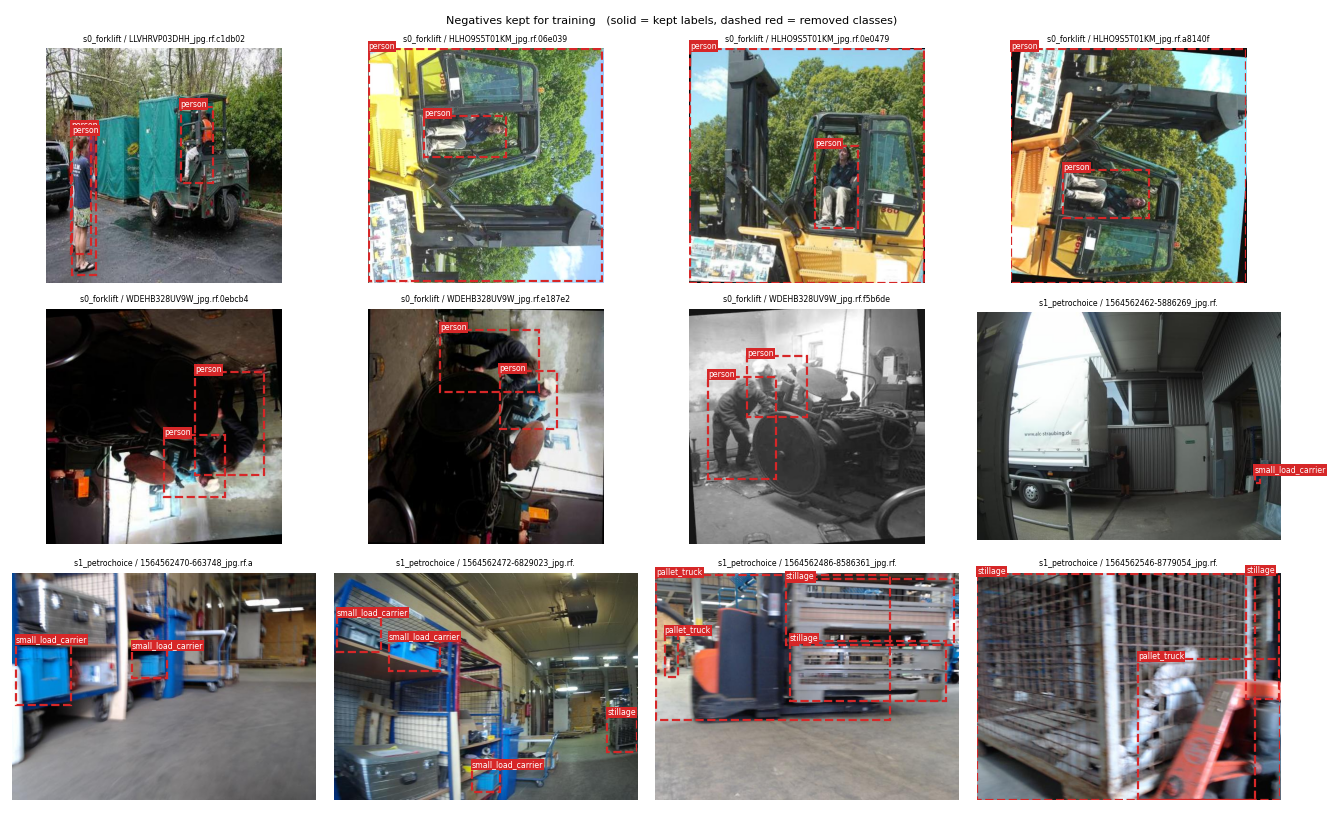

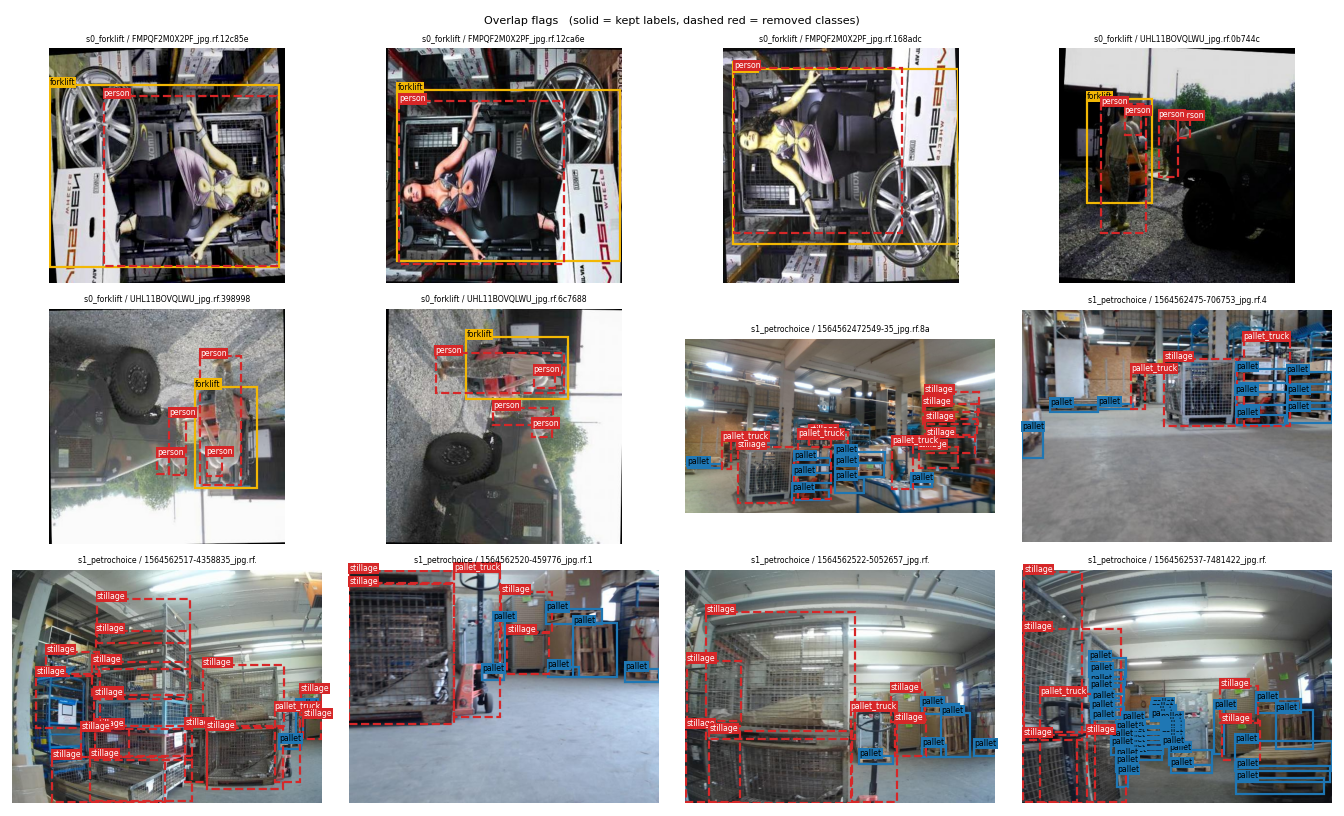

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

== Verification (re-read from disk) ==
                        split images label_files forklift   pallet invalid_lines
                        train   1868      1868.0   1005.0  11776.0           0.0
                        valid    215       215.0     96.0   1499.0           0.0
ultralytics check_det_dataset     ok                                            
All checks passed: image/label pairs, class ids 0/1, box ranges, counts, data.yaml.

Ready: /kaggle/working/warehouse_2cls/data.yaml


In [3]:
DATA_YAML = main()
DATA = OUT_DIR

## 3. Split hygiene

There is **no usable test split** (source test splits were merged into train), so a new one is carved from the pooled train data. Frames that look almost identical (same scene, consecutive video frames) are grouped with a 64-bit difference hash and a group goes entirely to test or entirely stays in train. Then near-duplicates between train and validation or test are removed from train. Without this, a test twin of a training image makes the score look better than it is. A class with very few boxes is never forced into test, because that would leave nothing to train on.

The hash catches near-identical frames, not every similar frame, so the final numbers should still be read as optimistic for a new warehouse.

### 3.1 Settings

Near-duplicate distance, test fraction and the minimum boxes wanted per class in the test split.

In [ ]:
NEAR_DUP_DIST = 8        # max difference-hash distance (out of 64 bits) counted as the same scene
TEST_FRACTION = 0.10     # carve this share of train into a test split; 0 disables it
MIN_TEST_BOXES = 15      # try to have at least this many boxes of each class in test

### 3.2 Hashing and image helpers

Difference hash, Hamming distance, listing images, counting boxes and grouping near-duplicates.

In [ ]:
# 64-bit difference hash of an image: near-identical images get nearly identical hashes.
def dhash(path, size=8):
    im = Image.open(path).convert("L").resize((size + 1, size), Image.BILINEAR)
    a = np.asarray(im, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


# Count the set bits of each element (applied to an XOR of hashes this is the Hamming distance).
def popcount(x):
    return np.unpackbits(np.ascontiguousarray(x).view(np.uint8).reshape(-1, 8), axis=1).sum(1)


# Sorted list of the image files in a split.
def image_list(split):
    d = DATA / split / "images"
    return sorted(d.glob("*")) if d.exists() else []


# Count the boxes per class id in the label file of one image.
def count_boxes(split, p):
    lf = DATA / split / "labels" / (p.stem + ".txt")
    return Counter(int(ln.split()[0]) for ln in lf.read_text().splitlines() if ln.strip()) if lf.exists() else Counter()


# Group near-identical images (hash distance up to max_dist) so a group is never split across splits.
def clusters_of(paths, max_dist):
    h = np.array([dhash(p) for p in paths], dtype=np.uint64)
    parent = list(range(len(paths)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(len(paths) - 1):
        for j in np.nonzero(popcount(h[i + 1:] ^ h[i]) <= max_dist)[0]:
            parent[find(i + 1 + int(j))] = find(i)
    groups = {}
    for i, p in enumerate(paths):
        groups.setdefault(find(i), []).append(p)
    return list(groups.values())

### 3.3 Carve the test split and remove leakage

Create the test split from whole near-duplicate groups and drop twins across splits.

In [ ]:
# Create a test split from train by moving whole near-duplicate groups (skipped if a test split exists).
def carve_test(fraction):
    if fraction <= 0 or image_list("test"):
        print("test split: keeping the one from the source" if image_list("test") else "test split: disabled")
        return
    imgs = image_list("train")
    groups = clusters_of(imgs, NEAR_DUP_DIST)
    rng = random.Random(SEED)
    rng.shuffle(groups)
    target = round(fraction * len(imgs))
    train_total = sum((count_boxes("train", p) for p in imgs), Counter())
    # only force a minimum for classes that are common enough; a rare class must stay in train
    need = [c for c in (0, 1) if train_total[c] >= 5 * MIN_TEST_BOXES]
    chosen, counts, remaining = [], Counter(), list(groups)

    def take(g):
        for p in g:
            chosen.append(p)
            counts.update(count_boxes("train", p))

    while remaining and len(chosen) < target:
        take(remaining.pop())
    while remaining and len(chosen) < 2 * target and need and min(counts[c] for c in need) < MIN_TEST_BOXES:
        lacking = min(need, key=lambda c: counts[c])
        pick = next((g for g in remaining if any(count_boxes("train", p)[lacking] for p in g)), None)
        if pick is None:
            break
        remaining.remove(pick)
        take(pick)
    (DATA / "test" / "images").mkdir(parents=True, exist_ok=True)
    (DATA / "test" / "labels").mkdir(parents=True, exist_ok=True)
    for p in chosen:
        shutil.move(str(p), str(DATA / "test" / "images" / p.name))
        shutil.move(str(DATA / "train" / "labels" / (p.stem + ".txt")), str(DATA / "test" / "labels" / (p.stem + ".txt")))
    print(f"test split: {len(chosen)} images from {len(groups)} scene groups in train "
          f"(forklift boxes {counts[0]} of {train_total[0]}, pallet boxes {counts[1]} of {train_total[1]})")
    for c in (0, 1):
        if train_total[c] < 5 * MIN_TEST_BOXES:
            print(f"WARNING: only {train_total[c]} {CLASSES[c]} boxes exist, so the test set cannot measure {CLASSES[c]} reliably.")


# Images of `query` whose hash is within max_dist of any image in `ref`.
def near_dups(query, ref, max_dist):
    if not ref:
        return []
    ref_h = np.array([h for _, h in ref], dtype=np.uint64)
    return [p for p, h in query if popcount(ref_h ^ np.uint64(h)).min() <= max_dist]


# Delete near-duplicates across train, valid and test so no twin of a test image stays in training.
def remove_leakage(max_dist):
    hs = {sp: [(p, dhash(p)) for p in image_list(sp)] for sp in ("train", "valid", "test")}
    drop = {"train": near_dups(hs["train"], hs["valid"] + hs["test"], max_dist),
            "valid": near_dups(hs["valid"], hs["test"], max_dist)}
    for sp, files in drop.items():
        for p in files:
            p.unlink(missing_ok=True)
            (DATA / sp / "labels" / (p.stem + ".txt")).unlink(missing_ok=True)
        print(f"removed {len(files)} near-duplicate images from {sp}")


# Make data.yaml point to the test split when one exists.
def update_yaml():
    cfg = yaml.safe_load(open(DATA / "data.yaml"))
    if image_list("test"):
        cfg["test"] = "test/images"
    yaml.safe_dump(cfg, open(DATA / "data.yaml", "w"), sort_keys=False)

### 3.4 Run and summarise the splits

Apply the steps and show the final image and box counts per split.

In [5]:
carve_test(TEST_FRACTION)
remove_leakage(NEAR_DUP_DIST)
update_yaml()

SPLITS = [s for s in ("train", "valid", "test") if image_list(s)]
rows = []
for s in SPLITS:
    imgs = image_list(s)
    labs = {f.stem for f in (DATA / s / "labels").glob("*.txt")}
    assert {p.stem for p in imgs} == labs, f"{s}: image/label mismatch"
    c = sum((count_boxes(s, p) for p in imgs), Counter())
    rows.append(dict(split=s, images=len(imgs), empty_label_images=sum(not count_boxes(s, p) for p in imgs),
                     forklift=c[0], pallet=c[1]))
final = pd.DataFrame(rows)
display(final)

test split: keeping the one from the source
removed 0 near-duplicate images from train
removed 0 near-duplicate images from valid


,split,images,empty_label_images,forklift,pallet
0,train,1660,61,905,10347
1,valid,213,7,96,1480
2,test,187,11,100,1118


## 4. Exploratory analysis

Two things to read from these plots: class imbalance, and how small the boxes are. Small boxes are the reason to consider a larger image size or tiling.

### 4.1 Label and plotting helpers

Read ground-truth boxes, draw boxes and build a table of every label.

In [ ]:
# Read the ground-truth boxes of one image in pixel coordinates.
def read_gt(split, stem, W, H):
    out = []
    lf = DATA / split / "labels" / (stem + ".txt")
    if lf.exists():
        for ln in lf.read_text().splitlines():
            if not ln.strip():
                continue
            c, x, y, w, h = ln.split()
            x, y, w, h = float(x), float(y), float(w), float(h)
            out.append((int(c), (x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H))
    return out


# Draw boxes (with class name and score when present) on a matplotlib axis.
def draw(ax, boxes, style="-", color=None):
    for b in boxes:
        c, x0, y0, x1, y1 = b[:5]
        col = color or COLORS[c]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, ls=style, ec=col))
        txt = CLASSES[c] + (f" {b[5]:.2f}" if len(b) > 5 else "")
        ax.text(x0, y0, txt, fontsize=7, color="black", bbox=dict(fc=col, lw=0, pad=1))


# One row per label box in every split (class and size relative to the image).
def label_table():
    rows = []
    for sp in SPLITS:
        for lf in (DATA / sp / "labels").glob("*.txt"):
            for ln in lf.read_text().splitlines():
                if ln.strip():
                    c, x, y, w, h = ln.split()
                    rows.append(dict(split=sp, cls=CLASSES[int(c)], area=float(w) * float(h)))
    return pd.DataFrame(rows)

### 4.2 Box counts and size distribution

Boxes per split and class, and how small the boxes are compared with the image.

cls    forklift  pallet
split                  
test        100    1118
train       905   10347
valid        96    1480


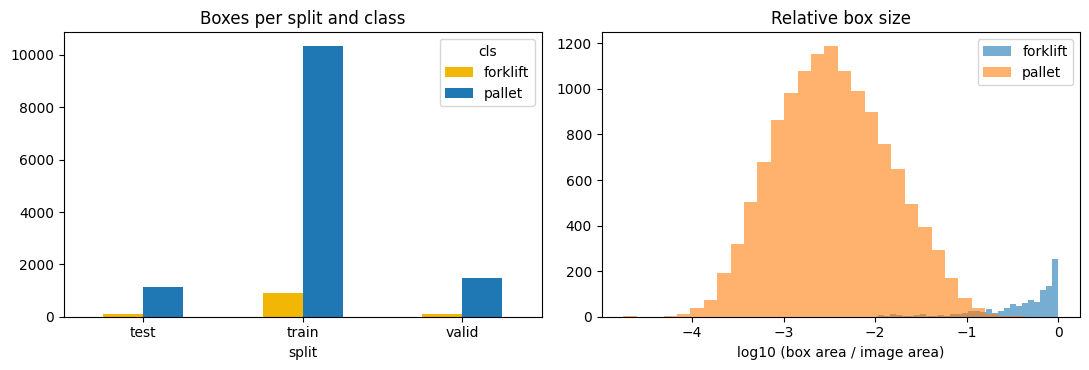

70.4% of boxes cover less than 1% of the image


In [6]:
df_labels = label_table()
counts = df_labels.pivot_table(index="split", columns="cls", values="area", aggfunc="count").fillna(0).astype(int)
print(counts)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
counts.plot.bar(ax=ax[0], rot=0, color=[COLORS[CLASSES.index(c)] for c in counts.columns])
ax[0].set_title("Boxes per split and class")
for c in CLASSES:
    sub = df_labels[df_labels.cls == c]
    if len(sub):
        ax[1].hist(np.log10(sub.area.clip(lower=1e-6)), bins=30, alpha=0.6, label=c)
ax[1].set_xlabel("log10 (box area / image area)"); ax[1].legend(); ax[1].set_title("Relative box size")
plt.tight_layout(); plt.show()
print(f"{(df_labels.area < 0.01).mean():.1%} of boxes cover less than 1% of the image")

### 4.3 Sample training images

Random training images with their ground-truth boxes.

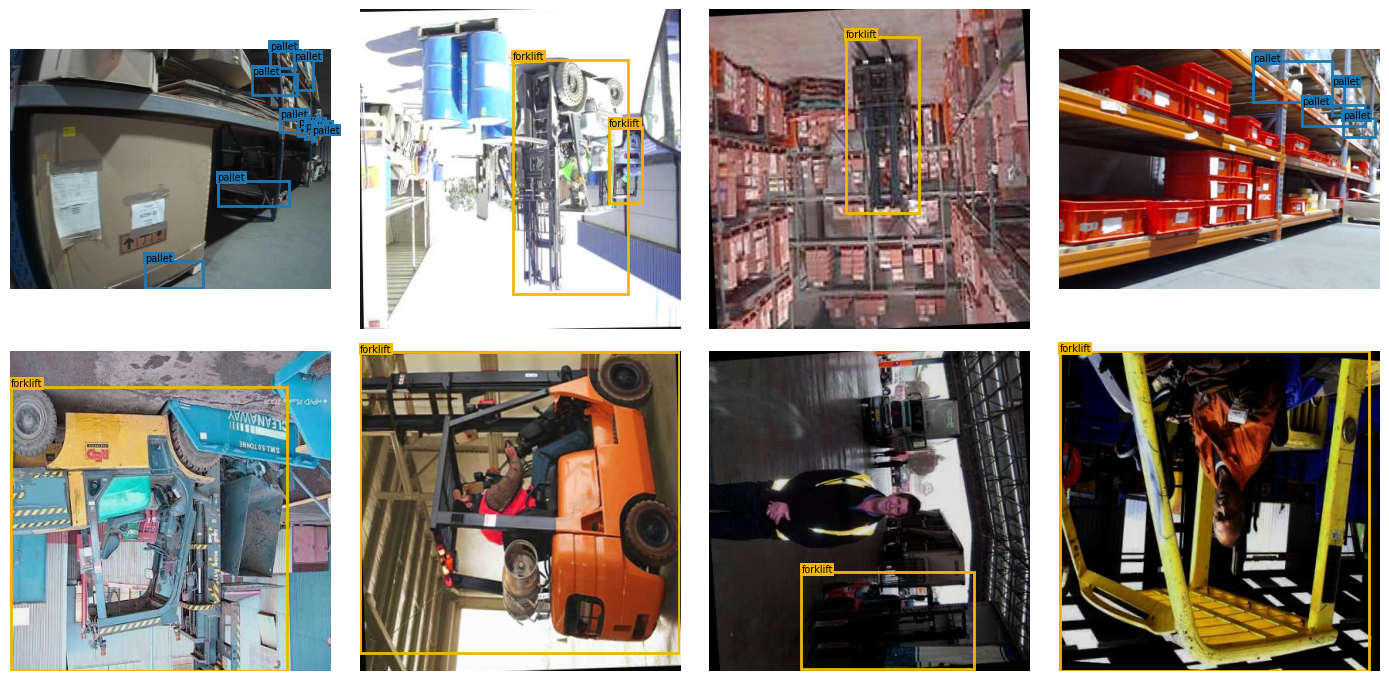

In [6]:
files = [p for p in image_list("train") if count_boxes("train", p)]
picks = random.Random(SEED).sample(files, min(8, len(files)))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, f in zip(axes.flat, picks):
    im = Image.open(f).convert("RGB"); W, H = im.size
    ax.imshow(im); draw(ax, read_gt("train", f.stem, W, H)); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Training

**Class imbalance.** The train split has roughly 11 pallet boxes for every forklift box. Three remedies are used, and none touches the validation or test labels:

1. **Oversampling (this cell).** Train images that contain the rarest class are repeated (the factor is about the square root of the imbalance ratio, at most `MAX_REPEAT`). No data is thrown away, and augmentation makes each repeat look different. Under-sampling the common class was rejected because it would discard useful pallet examples.
2. **Class-weighted loss (`CLS_PW`).** The classification loss gives the rarer class a larger weight, in proportion to its remaining shortage after oversampling.
3. **Self-training with confident pseudo-labels (section 5b, optional).** The forklift dataset never annotates pallets and the warehouse dataset almost never annotates forklifts. A first model finds the missing objects, and only its confident detections are added as labels.

Metrics are reported per class (AP per class), because overall accuracy hides a weak minority class.

### 5.1 Source helpers and IoU

Tell which dataset an image came from and compute box overlap.

In [ ]:
# Source dataset of an image, taken from its file-name prefix (the copy prefix `repN_` is ignored).
def source_of(name):
    return re.sub(r"^rep\d+_", "", name).split("__")[0]


# True for oversampled copies (file names that start with `repN_`).
def is_copy(p):
    return re.match(r"^rep\d+_", p.name) is not None


# Intersection over union of two boxes given as (x0, y0, x1, y1).
def iou_xyxy(a, b):
    ix0, iy0, ix1, iy1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix1 - ix0) * max(0.0, iy1 - iy0)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


# Box counts per class for each source dataset, ignoring oversampled copies.
def boxes_per_source(splits):
    out = {}
    for sp in splits:
        for p in image_list(sp):
            if not is_copy(p):
                out.setdefault(source_of(p.name), Counter()).update(count_boxes(sp, p))
    return out

### 5.2 Boxes per source

How many boxes of each class every source dataset provides.

In [7]:
# boxes of each class per source, measured before any oversampling or pseudo-labels
SRC_BOXES = boxes_per_source(SPLITS)
display(pd.DataFrame({s: {CLASSES[c]: cnt[c] for c in range(len(CLASSES))} for s, cnt in SRC_BOXES.items()}).T)

,forklift,pallet
s0_forklift,1096,0
s1_petrochoice,5,12945


### 5.3 Class-imbalance fix: repeat the rarest class

Repeat train images that contain the rarest class (images only, labels are unchanged).

In [ ]:
# Repeat train images that contain the rarest class up to max_repeat times (safe to re-run).
def oversample_rare(max_repeat):
    img_dir, lab_dir = DATA / "train" / "images", DATA / "train" / "labels"
    for p in [p for p in image_list("train") if is_copy(p)]:      # idempotent: drop copies of an earlier run
        p.unlink()
        (lab_dir / (p.stem + ".txt")).unlink(missing_ok=True)
    per_img = {p: count_boxes("train", p) for p in image_list("train")}
    tot = sum(per_img.values(), Counter())
    present = {c: tot[c] for c in range(len(CLASSES)) if tot[c] > 0}
    if len(present) < 2:
        return 1
    rare = min(present, key=present.get)
    k = int(min(max_repeat, max(1, round((max(present.values()) / present[rare]) ** 0.5))))
    for p, cnt in per_img.items():
        if cnt[rare] > 0:
            for j in range(1, k):
                shutil.copy2(p, img_dir / f"rep{j}_{p.name}")
                shutil.copy2(lab_dir / (p.stem + ".txt"), lab_dir / f"rep{j}_{p.stem}.txt")
    return k

### 5.4 Apply the oversampling

Run the repetition and print the resulting train size.

In [7]:
REPEAT_K = oversample_rare(MAX_REPEAT) if OVERSAMPLE else 1
tc = sum((count_boxes("train", p) for p in image_list("train")), Counter())
print(f"images with the rarest class are repeated x{REPEAT_K}. Train now: {len(image_list('train'))} images, "
      f"{tc[0]} forklift boxes, {tc[1]} pallet boxes")

images with the rarest class are repeated x3. Train now: 3324 images, 2715 forklift boxes, 10347 pallet boxes


### Training

Two experiments (three with `TRY_MEDIUM`), same data and settings, only the model size changes. Fine-tuning starts from COCO weights (transfer learning).

* `PRESET` sets the image size, epochs and patience. In the first runs 70% of the boxes covered less than 1% of the image and the strict mAP was still rising at the last epoch, so the **accurate** preset uses a larger image (960 px) and a longer schedule (100 epochs). **fast** is 768 px and 60 epochs.
* `cos_lr`: smooth learning-rate decay for a stable end of training.
* `cls_pw`: class-weighted classification loss (see above).
* `close_mosaic=10`: mosaic augmentation is switched off for the last 10 epochs so the model finishes on natural images.
* `flipud=0`: a vertically flipped forklift is not realistic. Horizontal flip is kept.
* `batch=-1`: the largest batch that fits in GPU memory. `seed` is fixed for repeatability.

To add RT-DETR as another experiment: `from ultralytics import RTDETR` and train `RTDETR("rtdetr-l.pt")`. It is heavier, so only do it if time allows.

In [8]:
from ultralytics import YOLO

EXPERIMENTS = [
    dict(name="yolo11n", weights="yolo11n.pt"),
    dict(name="yolo11s", weights="yolo11s.pt"),
]
if TRY_MEDIUM:
    EXPERIMENTS.append(dict(name="yolo11m", weights="yolo11m.pt"))
COMMON = dict(data=str(DATA / "data.yaml"), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, patience=PATIENCE, seed=SEED,
              device=DEVICE, workers=2, project=str(RUNS), exist_ok=True, close_mosaic=10,
              fliplr=0.5, flipud=0.0, cos_lr=True, cls_pw=CLS_PW, plots=True)

for e in EXPERIMENTS:
    t0 = time.time()
    YOLO(e["weights"]).train(name=e["name"], **COMMON)
    free_gpu()
    print(f"{e['name']} trained in {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.5, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/warehouse_2cls/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n, nbs=64, nms=None, opset=None, optimize=Fa

### 5b. Self-training: fill in the missing labels

A class is treated as **not annotated** in a source if that source has fewer than `MIN_SOURCE_BOXES` boxes of it (see the table above). In those images the objects exist but are labeled as background, which teaches the model the wrong thing.

Procedure: the teacher (`yolo11s` from the step above) predicts on the **train** images of those sources, and every detection of the missing class with confidence of at least `PSEUDO_CONF` is added as a label. A box is skipped if it is mostly the same object as an existing label of another class. A new `yolo11s_pl` model is then trained from the COCO weights (not from the teacher), so errors are not compounded.

* Only the train split is changed. Validation and test labels stay as annotated by humans.
* The original labels are backed up in `train/labels_before_pseudo` and restored if the cell is run again.
* **Look at the sample figure below.** Pseudo-labels are model guesses. If the boxes are clearly wrong, set `PSEUDO_LABEL = False` or raise `PSEUDO_CONF`.
* Validation and test cannot give credit for the new labels, because they were not added there. A gain on pallet recall may therefore show up only partly in the numbers.

### 5b.1 Settings

Teacher model and counter of the labels added.

In [ ]:
PL_TEACHER = "yolo11s"
PL_ADDED = Counter()

### 5b.2 Pseudo-label function

Predict on the train images and add confident boxes of missing classes (train split only).

In [ ]:
# Optional self-training: a first model adds confident labels to the TRAIN split only (originals are backed up).
def pseudo_label(teacher_pt, conf):
    lab_dir = DATA / "train" / "labels"
    bak = DATA / "train" / "labels_before_pseudo"
    if bak.exists():                      # restore the originals so a re-run never stacks pseudo-labels
        for f in bak.glob("*.txt"):
            shutil.copy2(f, lab_dir / f.name)
    else:
        shutil.copytree(lab_dir, bak)

    missing = {c: {s for s, cnt in SRC_BOXES.items() if cnt[c] < MIN_SOURCE_BOXES} for c in range(len(CLASSES))}
    for c, srcs in missing.items():
        print(f"{CLASSES[c]} is not annotated in: {sorted(srcs) or 'none'}")
    targets = [(p, [c for c in missing if source_of(p.name) in missing[c]]) for p in image_list("train")]
    targets = [(p, need) for p, need in targets if need]
    if not targets:
        return Counter(), {}

    free_gpu()
    teacher = YOLO(str(teacher_pt))
    preds = teacher.predict([str(p) for p, _ in targets], conf=conf, iou=0.6, imgsz=IMGSZ, stream=True,
                            verbose=False, device=DEVICE)
    added, examples = Counter(), {c: [] for c in range(len(CLASSES))}
    for (p, need), r in zip(targets, preds):
        H, W = r.orig_shape
        gt = read_gt("train", p.stem, W, H)
        new = []
        for c, xyxy, s, xywhn in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.xywhn.tolist()):
            c = int(c)
            if c not in need:
                continue
            if any(g[0] != c and iou_xyxy(xyxy, g[1:5]) >= 0.7 for g in gt):    # same object as a label of another class
                continue
            if any(g[0] == c and iou_xyxy(xyxy, g[1:5]) >= 0.5 for g in gt):    # already labeled
                continue
            new.append((c, xyxy, s, xywhn))
        if new:
            lf = lab_dir / (p.stem + ".txt")
            text = lf.read_text() if lf.exists() else ""
            if text and not text.endswith("\n"):
                text += "\n"
            text += "".join(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n" for c, _, _, (x, y, w, h) in new)
            lf.write_text(text)
            for c, xyxy, s, _ in new:
                added[c] += 1
                if len(examples[c]) < 6 and not is_copy(p):
                    examples[c].append((p, [(c, *xyxy, s)]))
    return added, examples

### 5b.3 Run (only when PSEUDO_LABEL is True)

The step is switched off in the final run.

In [9]:
if PSEUDO_LABEL:
    PL_ADDED, examples = pseudo_label(RUNS / PL_TEACHER / "weights" / "best.pt", PSEUDO_CONF)
    print("pseudo-labeled boxes added to train:", {CLASSES[c]: n for c, n in PL_ADDED.items()} or "none")
    for c, ex in examples.items():
        if ex:
            fig, axes = plt.subplots(2, 3, figsize=(15, 8))
            for ax in axes.flat:
                ax.axis("off")
            for ax, (p, bx) in zip(axes.flat, ex):
                ax.imshow(Image.open(p).convert("RGB"))
                draw(ax, bx, style="--", color="#d62728")
                ax.set_title(f"new {CLASSES[c]} label (dashed red)", fontsize=9)
            plt.tight_layout(); plt.show()
    if sum(PL_ADDED.values()):
        EXPERIMENTS.append(dict(name=f"{PL_TEACHER}_pl", weights=f"{PL_TEACHER}.pt"))
        t0 = time.time()
        YOLO(EXPERIMENTS[-1]["weights"]).train(name=EXPERIMENTS[-1]["name"], **COMMON)
        free_gpu()
        print(f"{EXPERIMENTS[-1]['name']} trained in {(time.time() - t0) / 60:.1f} min")
    else:
        print("nothing to add, no extra model trained")
else:
    print("PSEUDO_LABEL is off.")

PSEUDO_LABEL is off.


## 6. Evaluation

The model is **chosen on the validation set** and the test set is used **once** for the final number. Metrics are computed with a low confidence threshold (0.001), which is the standard way to get a proper mAP. Precision and recall here are the values at the best-F1 point of that run; section 7 reports them at a fixed, deployable threshold.

* mAP@0.5: lenient, did we find the object roughly in the right place.
* mAP@0.5:0.95: strict, rewards tight boxes.
* Precision: how many alarms were real. Recall: how many real objects were found.

**NMS overlap threshold.** After prediction, two boxes of the same class are merged when they overlap more than `NMS_IOU`. Pallets are stacked and stand side by side, so a low value deletes real neighbours, and a high value keeps duplicates. The best value is picked **on validation only**, then used for everything that follows. It needs no retraining.

### 6.1 Evaluation setup and helper

Which splits are evaluated and the function that validates one model.

In [ ]:
HAS_TEST = bool(image_list("test"))
EVAL_KEYS = ["val", "test"] if HAS_TEST else ["val"]      # keys in data.yaml
FINAL_KEY = EVAL_KEYS[-1]
FINAL_DIR = {"val": "valid", "test": "test"}[FINAL_KEY]   # folder on disk
if not HAS_TEST:
    print("WARNING: no test split. Final numbers come from validation, which was also used to pick the model.")


# Validate a trained model on a split and return one row of metrics (overall and per class).
def evaluate(name, split, iou=None, plots=True, tag=""):
    m = YOLO(str(RUNS / name / "weights" / "best.pt"))
    r = m.val(data=str(DATA / "data.yaml"), split=split, imgsz=IMGSZ, conf=0.001, iou=NMS_IOU if iou is None else iou,
              plots=plots, project=str(RUNS), name=f"{name}_{split}{tag}", exist_ok=True, verbose=False, device=DEVICE)
    row = dict(model=name, split=split, precision=r.box.mp, recall=r.box.mr, map50=r.box.map50, map5095=r.box.map,
               ms_per_img=sum(r.speed.values()))
    for k, ci in enumerate(r.box.ap_class_index):
        row[f"ap50_{CLASSES[int(ci)]}"] = r.box.ap50[k]
        row[f"map5095_{CLASSES[int(ci)]}"] = r.box.maps[int(ci)]
    return row

### 6.2 Compare all models

Validate every trained model and select the best one on validation.

In [10]:
free_gpu()
results = pd.DataFrame([evaluate(e["name"], sp) for e in EXPERIMENTS for sp in EVAL_KEYS])
display(results.round(3))

best_name = results[results.split == "val"].sort_values("map5095", ascending=False).iloc[0]["model"]
print("selected on validation:", best_name)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1199.3±277.4 MB/s, size: 32.6 KB)
val: Scanning /kaggle/working/warehouse_2cls/valid/labels.cache... 213 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 213/213 52.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.0it/s 4.6s0.2s
                   all        213       1576      0.855      0.773       0.83      0.476
Speed: 1.9ms preprocess, 9.5ms inference, 0.0ms loss, 4.1ms postprocess per image
Results saved to /kaggle/working/runs/yolo11n_val
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1729.6±1294.0 MB/s, size: 66.8 KB)

,model,split,precision,recall,map50,map5095,ms_per_img,ap50_forklift,map5095_forklift,ap50_pallet,map5095_pallet
0,yolo11n,val,0.855,0.773,0.830,0.476,15.516,0.852,0.510,0.807,0.441
1,yolo11n,test,0.869,0.806,0.875,0.548,15.477,0.946,0.664,0.805,0.432
2,yolo11s,val,0.867,0.778,0.838,0.491,21.033,0.854,0.531,0.821,0.452
3,yolo11s,test,0.826,0.793,0.863,0.540,22.888,0.902,0.631,0.823,0.450


selected on validation: yolo11s


### 6.3 Tune the NMS overlap threshold on validation

Try several NMS IoU values and keep 0.7 unless another is clearly better.

In [10]:
# tune the NMS overlap threshold on VALIDATION only
tune = pd.DataFrame([dict(nms_iou=v, **{k: evaluate(best_name, "val", iou=v, plots=False, tag=f"_nms{v}")[k]
                                         for k in ("precision", "recall", "map50", "map5095")})
                     for v in (0.5, 0.6, 0.7, 0.8)])
display(tune.round(3))
base_score = tune.loc[tune.nms_iou == NMS_IOU, "map5095"].iloc[0]
top = tune.sort_values("map5095", ascending=False).iloc[0]
if top.map5095 - base_score >= 0.002:        # only move away from the default for a clear gain
    NMS_IOU = float(top.nms_iou)
print("NMS overlap threshold used from here on:", NMS_IOU)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2409.3±1051.3 MB/s, size: 151.7 KB)
val: Scanning /kaggle/working/warehouse_2cls/valid/labels.cache... 213 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 213/213 47.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.8it/s 3.7s0.3s
                   all        213       1576      0.879      0.784      0.838      0.476
Speed: 1.0ms preprocess, 11.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1524.4±567.6 MB/s, size: 66.9 KB)
val: Scanning /kaggle/working/warehouse_2cls/

,nms_iou,precision,recall,map50,map5095
0,0.5,0.879,0.784,0.838,0.476
1,0.6,0.878,0.780,0.840,0.486
2,0.7,0.867,0.778,0.838,0.491
3,0.8,0.833,0.771,0.822,0.488


NMS overlap threshold used from here on: 0.7


### 6.4 Final evaluation of the selected model

Metrics of the selected model on validation and test (the test set is used once).

In [10]:
# final numbers of the selected model with that threshold
final_eval = pd.DataFrame([evaluate(best_name, sp, plots=(sp == FINAL_KEY), tag="_final") for sp in EVAL_KEYS])
display(final_eval.round(3))
best_val = final_eval[final_eval.split == "val"].iloc[0]
best_test = final_eval[final_eval.split == FINAL_KEY].iloc[0]

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1671.6±1149.8 MB/s, size: 108.9 KB)
val: Scanning /kaggle/working/warehouse_2cls/valid/labels.cache... 213 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 213/213 49.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.4it/s 4.2s0.3s
                   all        213       1576      0.867      0.778      0.838      0.491
Speed: 1.0ms preprocess, 13.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 909.7±244.9 MB/s, size: 29.9 KB)
val: Scanning /kaggle/working/warehouse_2cls/t

,model,split,precision,recall,map50,map5095,ms_per_img,ap50_forklift,map5095_forklift,ap50_pallet,map5095_pallet
0,yolo11s,val,0.867,0.778,0.838,0.491,15.760,0.854,0.531,0.821,0.452
1,yolo11s,test,0.826,0.793,0.863,0.540,22.531,0.902,0.631,0.823,0.450


### 6.5 Test-time augmentation check and training curves

Optional TTA check on validation, then the training curves.

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1155.1±182.0 MB/s, size: 35.8 KB)
val: Scanning /kaggle/working/warehouse_2cls/valid/labels.cache... 213 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 213/213 44.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.1it/s 6.8s0.5s
                   all        213       1576      0.859      0.753      0.832      0.507
Speed: 1.0ms preprocess, 26.1ms inference, 0.0ms loss, 0.9ms postprocess per image
test-time augmentation on validation: mAP@0.5:0.95 0.507 against 0.491 without it


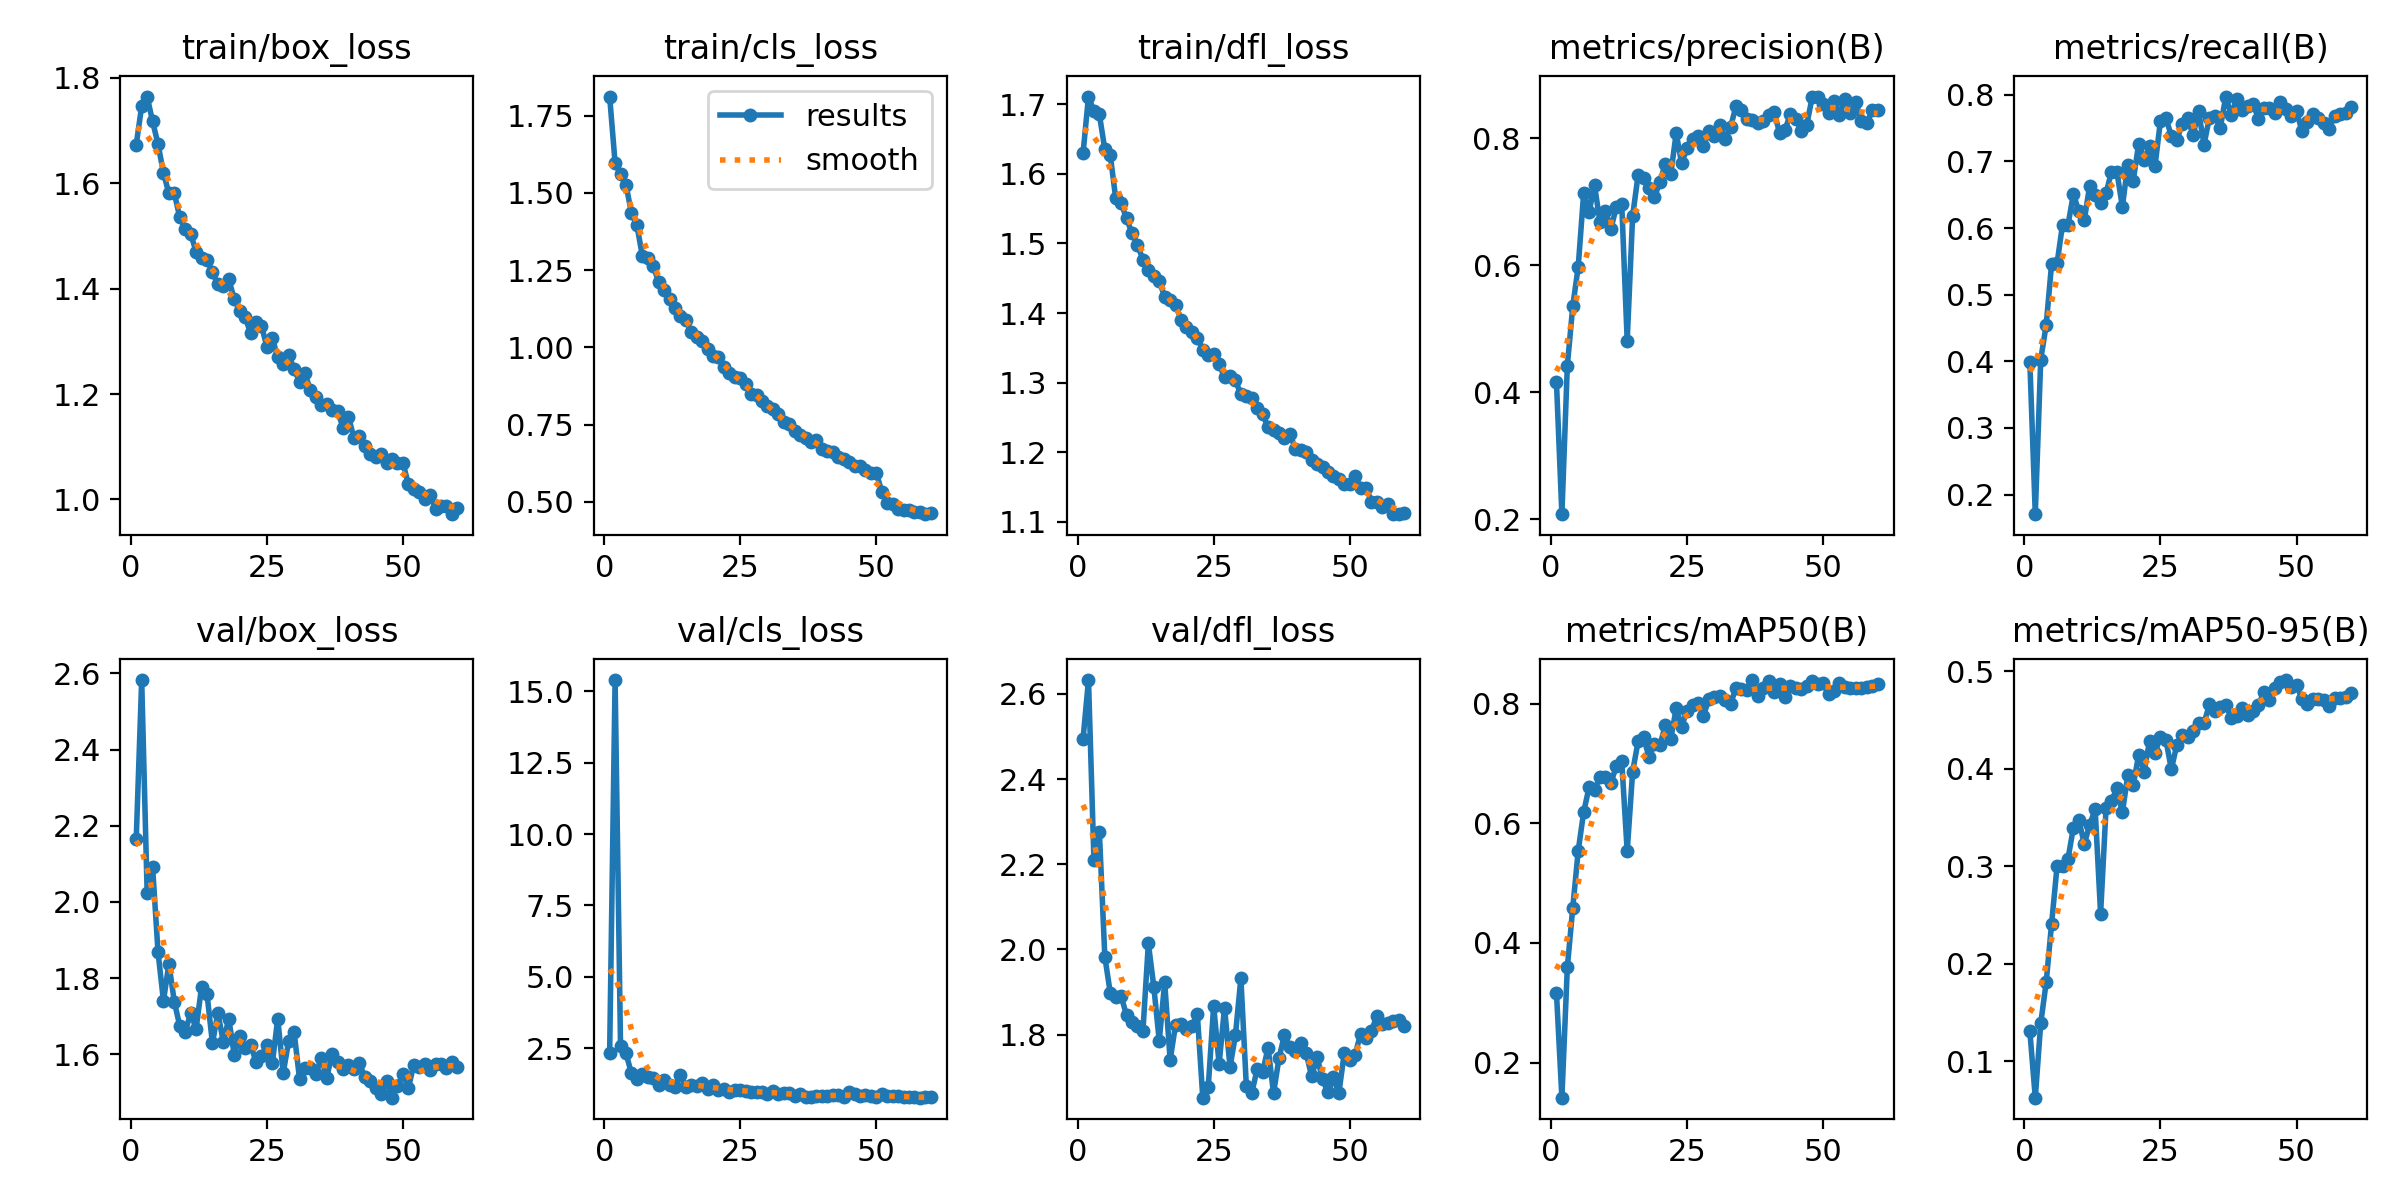

In [10]:
# test-time augmentation: reported on validation only, it is slower so it is not part of the pipeline
r_tta = YOLO(str(RUNS / best_name / "weights" / "best.pt")).val(
    data=str(DATA / "data.yaml"), split="val", imgsz=IMGSZ, conf=0.001, iou=NMS_IOU, augment=True, plots=False,
    verbose=False, device=DEVICE)
print(f"test-time augmentation on validation: mAP@0.5:0.95 {r_tta.box.map:.3f} against {best_val.map5095:.3f} without it")

img = RUNS / best_name / "results.png"
if img.exists():
    display(IPImage(filename=str(img), width=700))

## 7. Error analysis

Numbers hide where the model fails, so the final split is analysed box by box. A prediction counts as correct if it overlaps a label of the same class with IoU of at least 0.5. Matching goes from the most confident prediction down, and each label is used once.

**Operating threshold.** Section 6 uses a very low confidence threshold, which is right for mAP but not for a deployed system. Here the threshold is **chosen on the validation set** (best F1) and then applied unchanged to the final split.

**Confusion matrix.** The matrix Ultralytics draws is computed at confidence 0.001, so it is flooded with background false alarms and says little. The one below is built at the chosen threshold, from the same matching rule as everything else here:

* rows are the true class, columns are the predicted class;
* the **background row** counts false alarms (the model predicted an object where there is none);
* the **background column** counts missed objects;
* a **forklift row, pallet column** cell means a forklift was called a pallet.

**Why is mAP@0.5:0.95 low?** Two things can cap it, and the tables below separate them. (1) Objects that are never found, mostly small ones: see recall by object size. (2) Boxes that are found but not tight: see the median IoU of correct detections. If the median IoU is around 0.8 the boxes are tight. If it is closer to 0.65, the strict metric is limited by loose boxes, partly caused by the labels themselves (polygons were converted to boxes, and stacked pallets are hard to outline).

**Per-source check.** The forklift labels come from one dataset and the pallet labels from another, so a model could score well just by recognising which dataset an image came from. The per-source table splits the results. The last part lists confident predictions of a class in sources that barely annotate it. If those are real objects, labels are missing there and the false positives are partly the labels' fault.

### 7.1 Collect predictions

Run the model on a split and keep predictions with their labels.

In [ ]:
# Run the model on a split and keep every prediction together with its labels.
def predict_store(model, folder, conf=0.05, chunk=16):
    """Predictions for every image of a split, kept with their labels. Works in small chunks and falls back to the CPU
    for a chunk if the GPU runs out of memory."""
    files = image_list(folder)
    store, cpu_model = {}, None
    free_gpu()
    for i in range(0, len(files), chunk):
        part = files[i:i + chunk]
        kw = dict(conf=conf, iou=NMS_IOU, imgsz=IMGSZ, verbose=False)
        try:
            preds = model.predict([str(f) for f in part], device=DEVICE, **kw)
        except RuntimeError as err:
            if "out of memory" not in str(err).lower():
                raise
            free_gpu()
            cpu_model = cpu_model or YOLO(str(model.ckpt_path))
            preds = cpu_model.predict([str(f) for f in part], device="cpu", **kw)
        for f, r in zip(part, preds):
            H, W = r.orig_shape
            gt = read_gt(folder, f.stem, W, H)
            pr = [(int(c), b[0], b[1], b[2], b[3], float(s))
                  for c, b, s in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist(), r.boxes.conf.tolist())]
            store[f.name] = (f, gt, pr, (W, H))
    return store

### 7.2 Match predictions to labels

Greedy matching that also detects class confusions.

In [ ]:
# Match the predictions of one image to its labels (greedy, most confident first) and return the events.
def match_image(gt, pr, conf, thr=0.5):
    """Greedy matching, most confident prediction first. A same-class label is tried first, then a label of
    another class (a class confusion). Returns events (kind, gt_class, pred_class, gt_index, iou)."""
    used, ev = set(), []
    for p in sorted((p for p in pr if p[5] >= conf), key=lambda t: -t[5]):
        best, best_iou, same_class = None, 0.0, False
        for same in (True, False):
            bi, bj = 0.0, None
            for j, g in enumerate(gt):
                if j in used or (g[0] == p[0]) != same:
                    continue
                v = iou_xyxy(p[1:5], g[1:5])
                if v >= thr and v > bi:
                    bi, bj = v, j
            if bj is not None:
                best, best_iou, same_class = bj, bi, same
                break
        if best is None:
            ev.append(("fp", None, p[0], None, None))                  # background called an object
        else:
            used.add(best)
            ev.append(("tp" if same_class else "wrong", gt[best][0], p[0], best, best_iou))
    ev += [("fn", g[0], None, j, None) for j, g in enumerate(gt) if j not in used]   # missed objects
    return ev

### 7.3 Scoring helpers

Confusion matrix, precision / recall / F1 and localisation quality.

In [ ]:
# Confusion matrix and per-image error table at a given confidence.
def score(store, conf, thr=0.5):
    n = len(CLASSES)
    cm = np.zeros((n + 1, n + 1), dtype=int)        # rows: true class (last = background), cols: predicted (last = background)
    recs, missed_area = [], []
    for name, (f, gt, pr, (W, H)) in store.items():
        row = dict(file=name, source=source_of(name), gt=len(gt), wrong_class=0)
        for c in CLASSES:
            row[f"tp_{c}"] = row[f"fp_{c}"] = row[f"fn_{c}"] = 0
        for kind, gk, pk, j, _ in match_image(gt, pr, conf, thr):
            if kind == "tp":
                row[f"tp_{CLASSES[pk]}"] += 1; cm[gk, pk] += 1
            elif kind == "wrong":                      # counts as a false alarm of the predicted class and a miss of the true class
                row[f"fp_{CLASSES[pk]}"] += 1; row[f"fn_{CLASSES[gk]}"] += 1; row["wrong_class"] += 1; cm[gk, pk] += 1
            elif kind == "fp":
                row[f"fp_{CLASSES[pk]}"] += 1; cm[n, pk] += 1
            else:
                row[f"fn_{CLASSES[gk]}"] += 1; cm[gk, n] += 1
                g = gt[j]; missed_area.append((g[3] - g[1]) * (g[4] - g[2]) / (W * H))
        row.update(tp=sum(row[f"tp_{c}"] for c in CLASSES), fp=sum(row[f"fp_{c}"] for c in CLASSES),
                   fn=sum(row[f"fn_{c}"] for c in CLASSES))
        recs.append(row)
    return pd.DataFrame(recs), cm, missed_area


# Precision, recall and F1 from the error table.
def prf(err):
    tp, fp, fn = int(err.tp.sum()), int(err.fp.sum()), int(err.fn.sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


# One row per label: found or not, how tight the box is (IoU) and how large the object is.
def loc_quality(store, conf):
    """One row per label: was it found, how tight was the box (IoU), and how large is the object."""
    rows = []
    for name, (f, gt, pr, (W, H)) in store.items():
        for kind, gk, pk, j, v in match_image(gt, pr, conf):
            if kind in ("tp", "wrong", "fn"):
                g = gt[j]
                rows.append(dict(cls=CLASSES[gk], found=(kind == "tp"), iou=v if kind == "tp" else np.nan,
                                 area=(g[3] - g[1]) * (g[4] - g[2]) / (W * H)))
    return pd.DataFrame(rows)

### 7.4 Choose the operating confidence on validation

Sweep the confidence threshold and pick the one with the best F1.

operating threshold chosen on validation: confidence 0.35


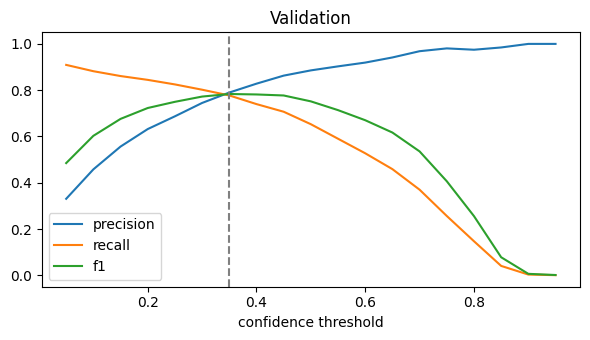

In [12]:
best_model = YOLO(str(RUNS / best_name / "weights" / "best.pt"))

# 1) choose the operating threshold on VALIDATION
store_val = predict_store(best_model, "valid")
sweep = pd.DataFrame([dict(conf=t, **dict(zip(("precision", "recall", "f1"), prf(score(store_val, t)[0]))))
                      for t in np.round(np.arange(0.05, 0.96, 0.05), 2)])
OP_CONF = float(sweep.loc[sweep.f1.idxmax(), "conf"])
print(f"operating threshold chosen on validation: confidence {OP_CONF:.2f}")
fig, ax = plt.subplots(figsize=(6, 3.5))
for k in ("precision", "recall", "f1"):
    ax.plot(sweep.conf, sweep[k], label=k)
ax.axvline(OP_CONF, color="grey", ls="--"); ax.set_xlabel("confidence threshold"); ax.legend(); ax.set_title("Validation")
plt.tight_layout(); plt.show()

### 7.5 Confusion matrix on the final split

Counts and normalised confusion matrix at the chosen threshold.

test, confidence 0.35: precision 0.775, recall 0.774, F1 0.775  (tp 943, fp 273, fn 275, wrong class 0)


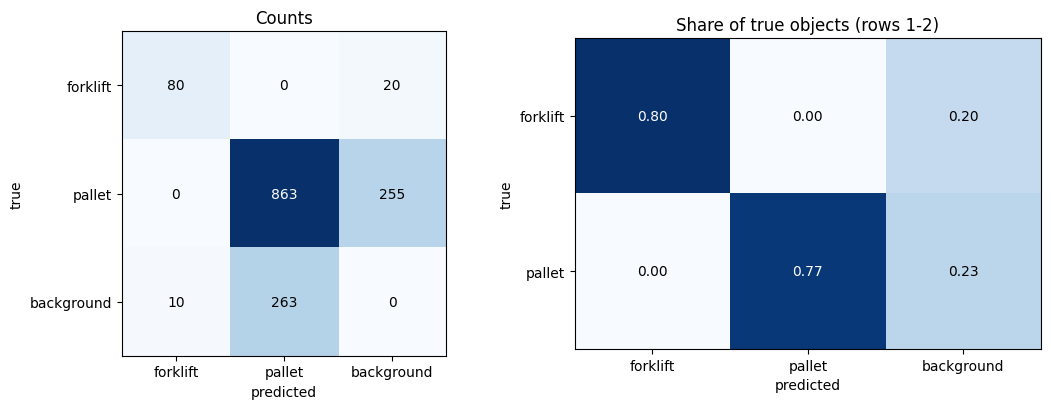

forklift called pallet: 0, pallet called forklift: 0, false alarms on background: 273, missed objects: 275


In [12]:
# 2) apply it to the final split
store = predict_store(best_model, FINAL_DIR)
err, cm, missed_area = score(store, OP_CONF)
op_p, op_r, op_f1 = prf(err)
print(f"{FINAL_KEY}, confidence {OP_CONF:.2f}: precision {op_p:.3f}, recall {op_r:.3f}, F1 {op_f1:.3f}  "
      f"(tp {int(err.tp.sum())}, fp {int(err.fp.sum())}, fn {int(err.fn.sum())}, wrong class {int(err.wrong_class.sum())})")

# 3) confusion matrix
names = CLASSES + ["background"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
panels = [("Counts", cm, "d"),
          ("Share of true objects (rows 1-2)", cm[:len(CLASSES)] / np.maximum(cm[:len(CLASSES)].sum(1, keepdims=True), 1), ".2f")]
for ax, (title, mat, fmt) in zip(axes, panels):
    ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(names[:mat.shape[0]])
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
plt.tight_layout(); plt.show()
n_cls = len(CLASSES)
print(f"forklift called pallet: {cm[0, 1]}, pallet called forklift: {cm[1, 0]}, "
      f"false alarms on background: {cm[n_cls, :n_cls].sum()}, missed objects: {cm[:n_cls, n_cls].sum()}")

### 7.6 Recall by object size and class

How often objects are found, split by class and by size.

In [12]:
# 4) why is mAP@0.5:0.95 low? objects not found (by size) and boxes that are found but loose
lq = loc_quality(store, OP_CONF)
lq["size"] = pd.cut(lq.area, [0, 0.002, 0.01, 1.0], labels=["small (<0.2% of image)", "medium (0.2-1%)", "large (>1%)"])
display(lq.groupby("cls").agg(objects=("found", "size"), share_found=("found", "mean"), median_iou_of_found=("iou", "median"),
                              share_iou_above_075=("iou", lambda s: (s.dropna() >= 0.75).mean())).round(3))
display(lq.pivot_table(index="size", columns="cls", values="found", aggfunc="mean", observed=False).round(3).add_prefix("share found: "))
display(lq.pivot_table(index="size", columns="cls", values="found", aggfunc="size", observed=False).add_prefix("objects: "))
if missed_area:
    final_areas = df_labels[df_labels.split == FINAL_DIR].area
    print(f"median relative area of missed objects: {np.median(missed_area):.4f} (all boxes in this split: {final_areas.median():.4f})")

,objects,share_found,median_iou_of_found,share_iou_above_075
cls,,,,
forklift,100,0.800,0.865,0.812
pallet,1118,0.772,0.791,0.620


cls,share found: forklift,share found: pallet
size,,
small (<0.2% of image),NaN,0.625
medium (0.2-1%),NaN,0.833
large (>1%),0.8,0.869


cls,objects: forklift,objects: pallet
size,,
small (<0.2% of image),0,376
medium (0.2-1%),0,467
large (>1%),100,275


median relative area of missed objects: 0.0019 (all boxes in this split: 0.0042)


### 7.7 Worst predictions

Images with the most missed objects and false alarms.

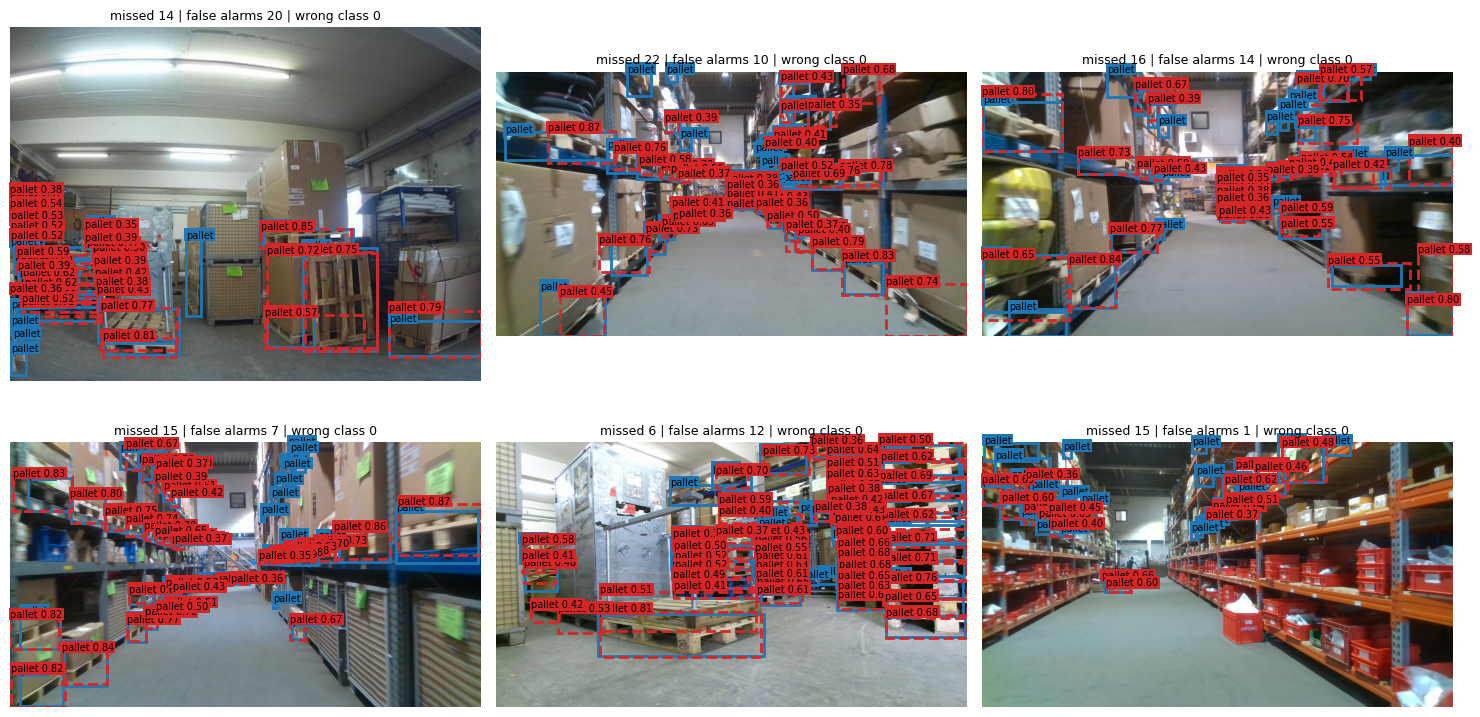

In [12]:
# 5) worst images
err["errors"] = err.fn + err.fp
worst = err.sort_values("errors", ascending=False).head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, name in zip(axes.flat, worst.file):
    f, gt, pr, _ = store[name]
    ax.imshow(Image.open(f).convert("RGB"))
    draw(ax, gt); draw(ax, [b for b in pr if b[5] >= OP_CONF], style="--", color="#d62728")
    row = err[err.file == name].iloc[0]
    ax.set_title(f"missed {row.fn} | false alarms {row.fp} | wrong class {row.wrong_class}", fontsize=9)
plt.tight_layout(); plt.show()

### 7.8 Errors per source

Errors split by source dataset (checks the source shortcut risk).

In [12]:
# 6) per-source results
cols = [f"{k}_{c}" for c in CLASSES for k in ("tp", "fp", "fn")]
by_src = err.groupby("source")[["gt"] + cols].sum()
for c in CLASSES:
    by_src[f"precision_{c}"] = by_src[f"tp_{c}"] / (by_src[f"tp_{c}"] + by_src[f"fp_{c}"]).replace(0, np.nan)
    by_src[f"recall_{c}"] = by_src[f"tp_{c}"] / (by_src[f"tp_{c}"] + by_src[f"fn_{c}"]).replace(0, np.nan)
display(by_src.round(2))

# 7) confident predictions of a class in sources that barely annotate it
for ci, cname in enumerate(CLASSES):
    for s in [s for s, cnt in SRC_BOXES.items() if cnt[ci] < MIN_SOURCE_BOXES]:
        hits = {n: [b for b in v[2] if b[0] == ci and b[5] >= 0.5] for n, v in store.items() if source_of(n) == s}
        hits = {n: b for n, b in hits.items() if b}
        n_src = sum(source_of(n) == s for n in store)
        print(f"{s}: {SRC_BOXES[s][ci]} labeled {cname} boxes. The model finds {sum(map(len, hits.values()))} confident {cname} boxes "
              f"in {len(hits)} of its {n_src} images in {FINAL_DIR}. If they are real, {cname} labels are missing in this source.")
        top = sorted(hits, key=lambda n: -len(hits[n]))[:6]
        if top:
            fig, axes = plt.subplots(2, 3, figsize=(15, 8))
            for ax in axes.flat:
                ax.axis("off")
            for ax, n in zip(axes.flat, top):
                ax.imshow(Image.open(store[n][0]).convert("RGB"))
                draw(ax, hits[n], style="--", color="#d62728")
                ax.set_title(f"{len(hits[n])} predicted {cname}, 0 labeled", fontsize=9)
            plt.tight_layout(); plt.show()

,gt,tp_forklift,fp_forklift,fn_forklift,tp_pallet,fp_pallet,fn_pallet,precision_forklift,recall_forklift,precision_pallet,recall_pallet
source,,,,,,,,,,,
s0_forklift,100,80,10,20,0,1,0,0.89,0.8,0.00,NaN
s1_petrochoice,1118,0,0,0,863,262,255,NaN,NaN,0.77,0.77


s1_petrochoice: 5 labeled forklift boxes. The model finds 0 confident forklift boxes in 0 of its 96 images in test. If they are real, forklift labels are missing in this source.
s0_forklift: 0 labeled pallet boxes. The model finds 0 confident pallet boxes in 0 of its 91 images in test. If they are real, pallet labels are missing in this source.


## 8. Speed and ONNX export

Latency is measured end to end for one image (preprocess + model + postprocess). It is measured on CPU for both the PyTorch and the ONNX model so the comparison is fair. The ONNX model is also re-evaluated to confirm that export did not change accuracy.

In [13]:
best_pt = RUNS / best_name / "weights" / "best.pt"
onnx_path = YOLO(str(best_pt)).export(format="onnx", imgsz=IMGSZ, simplify=True)
print("exported:", onnx_path)


def benchmark(weights, n=40, device="cpu"):
    m = YOLO(str(weights), task="detect")
    files = image_list(FINAL_DIR)[:n]
    m.predict(str(files[0]), imgsz=IMGSZ, verbose=False, device=device)  # warm-up
    t = [sum(m.predict(str(f), imgsz=IMGSZ, verbose=False, device=device)[0].speed.values()) for f in files]
    return float(np.mean(t)), float(np.percentile(t, 95))


rows = []
for label, w in (("PyTorch (CPU)", best_pt), ("ONNX (CPU)", onnx_path)):
    mean_ms, p95_ms = benchmark(w)
    rows.append(dict(model=label, mean_ms=mean_ms, p95_ms=p95_ms, fps=1000 / mean_ms))
speed = pd.DataFrame(rows)
display(speed.round(1))

onnx_val = YOLO(str(onnx_path), task="detect").val(data=str(DATA / "data.yaml"), split=FINAL_KEY, imgsz=IMGSZ, conf=0.001, iou=NMS_IOU,
                                                    device="cpu", verbose=False, plots=False)
print(f"ONNX {FINAL_KEY} mAP@0.5:0.95 = {onnx_val.box.map:.3f}  (PyTorch: {best_test.map5095:.3f})")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 30.9 GFLOPs

PyTorch: starting from '/kaggle/working/runs/yolo11s/weights/best.pt' with input shape (1, 3, 768, 768) BCHW and output shape(s) (1, 6, 12096) (18.3 MB)

ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.4s, saved as '/kaggle/working/runs/yolo11s/weights/best.onnx' (36.2 MB)

Export complete (3.1s)
Results saved to /kaggle/working/runs/yolo11s/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/yolo11s/weights/best.onnx imgsz=768 
Validate:        yolo val task=detect model=/kaggle/working/runs/yolo11s/weights/best.onnx imgsz=768 data=/kaggle/working/warehouse_2cls/data.yaml 
Visu

,model,mean_ms,p95_ms,fps
0,PyTorch (CPU),254.2,265.4,3.9
1,ONNX (CPU),210.1,219.6,4.8


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Loading /kaggle/working/runs/yolo11s/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 768, 768)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1447.6±1000.1 MB/s, size: 68.4 KB)
val: Scanning /kaggle/working/warehouse_2cls/test/labels.cache... 187 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 187/187 56.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 187/187 4.3it/s 43.4s0.2ss
                   all        187       1218      0.823      0.793      0.855      0.532
Speed: 1.4ms preprocess, 219.2ms inference, 0.0ms loss, 1.4ms postprocess per image
ONNX test mAP@0.5:0.95 = 0.532  (PyTorch: 0.540)


## 9. Download the weights

The cell below collects the trained weights of **every** model in one zip file: the PyTorch weights (`best.pt`, for inference or more training with Ultralytics), the ONNX export (runs without PyTorch, for deployment), the training curves and settings, and a short `HOW_TO_USE.txt`.

**To download from Kaggle:** run this cell, then open the **Output** section in the right panel (`/kaggle/working`) and download `forklift_pallet_weights.zip`. If the session may close, use **Save Version** and choose **Save & Run All**: the files then stay under the **Output** tab of the saved version.

The weights start from the COCO-pretrained Ultralytics weights, which are downloaded automatically the first time `YOLO("yolo11n.pt")` or `YOLO("yolo11s.pt")` is called.

In [14]:
from IPython.display import FileLink

PKG = WORK / "weights"
shutil.rmtree(PKG, ignore_errors=True)
PKG.mkdir(parents=True)
free_gpu()
for e in EXPERIMENTS:
    n = e["name"]
    wdir = RUNS / n / "weights"
    if not (wdir / "best.pt").exists():
        print("missing weights for", n)
        continue
    shutil.copy2(wdir / "best.pt", PKG / f"{n}_best.pt")
    try:
        shutil.copy2(YOLO(str(wdir / "best.pt")).export(format="onnx", imgsz=IMGSZ, simplify=True), PKG / f"{n}_best.onnx")
    except Exception as ex:
        print(f"ONNX export failed for {n}: {ex}")
    for extra in ("results.csv", "results.png", "args.yaml"):
        if (RUNS / n / extra).exists():
            shutil.copy2(RUNS / n / extra, PKG / f"{n}_{extra}")
shutil.copy2(DATA / "data.yaml", PKG / "data.yaml")
(PKG / "HOW_TO_USE.txt").write_text(f"""Forklift and pallet detector (Ultralytics YOLO11)

Classes: 0 = forklift, 1 = pallet
Image size: {IMGSZ}. Confidence threshold chosen on validation: {OP_CONF:.2f}. NMS IoU: {NMS_IOU}.
Best model on validation: {best_name}

    from ultralytics import YOLO
    model = YOLO("{best_name}_best.pt")      # or the other model's file
    results = model.predict("image.jpg", imgsz={IMGSZ}, conf={OP_CONF:.2f}, iou={NMS_IOU})
    results[0].show()

The .onnx files load the same way: YOLO("{best_name}_best.onnx", task="detect").
To train further: YOLO("{best_name}_best.pt").train(data="data.yaml", ...) after fixing the paths inside data.yaml.
The weights are fine-tuned from COCO-pretrained Ultralytics YOLO11 weights. Ultralytics is AGPL-3.0 and the datasets have
their own licenses, so check both before commercial use.
""")
shutil.make_archive(str(WORK / "forklift_pallet_weights"), "zip", PKG)
for f in sorted(PKG.iterdir()):
    print(f"{f.name:32s} {f.stat().st_size / 1e6:7.1f} MB")
print(f"\nforklift_pallet_weights.zip  {(WORK / 'forklift_pallet_weights.zip').stat().st_size / 1e6:.1f} MB")
display(FileLink("forklift_pallet_weights.zip"))

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 9.3 GFLOPs

PyTorch: starting from '/kaggle/working/runs/yolo11n/weights/best.pt' with input shape (1, 3, 768, 768) BCHW and output shape(s) (1, 6, 12096) (5.3 MB)

ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.5s, saved as '/kaggle/working/runs/yolo11n/weights/best.onnx' (10.2 MB)

Export complete (1.8s)
Results saved to /kaggle/working/runs/yolo11n/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/yolo11n/weights/best.onnx imgsz=768 
Validate:        yolo val task=detect model=/kaggle/working/runs/yolo11n/weights/best.onnx imgsz=768 data=/kaggle/working/warehouse_2cls/data.yaml 
Visualize:       https://netron.app
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11s summary (fused):

/kaggle/working/forklift_pallet_weights.zip

## 10. Video and tracking (optional)

Detection works on every frame independently, so boxes can flicker. ByteTrack gives each object a stable ID across frames, which also stops the same pallet from being counted twice. Set `VIDEO` to a short warehouse clip (upload it as a Kaggle dataset) to produce the demo.

In [ ]:
VIDEO = None  # for example "/kaggle/input/my-clip/warehouse.mp4"

if VIDEO and Path(VIDEO).exists():
    best_model.track(source=VIDEO, tracker="bytetrack.yaml", conf=OP_CONF, iou=NMS_IOU, imgsz=IMGSZ, save=True,
                     project=str(RUNS), name="video_demo", exist_ok=True, verbose=False, device=DEVICE)
    print("annotated video saved under", RUNS / "video_demo")
else:
    print("No video set. Skipping.")

## 11. Summary

The cell below prints the final numbers in the same shape as the submission text, so nothing is typed by hand.

In [15]:
r = best_test
by_class = ", ".join(f"{c}: AP50 {r[f'ap50_{c}']:.3f}, mAP50-95 {r[f'map5095_{c}']:.3f}" for c in CLASSES if f"ap50_{c}" in r and pd.notna(r[f"ap50_{c}"]))
onnx_ms = speed.loc[speed.model == "ONNX (CPU)", "mean_ms"].iloc[0]
n_img = final.set_index("split").images
split_name = "held-out test set" if HAS_TEST else "validation set (no separate test split)"
print(f"Model: Ultralytics {best_name}, COCO-pretrained, fine-tuned for up to {EPOCHS} epochs at {IMGSZ} px.")
if REPEAT_K > 1:
    print(f"Class imbalance: train images with the rarest class repeated x{REPEAT_K}; AP is reported per class.")
if sum(PL_ADDED.values()):
    print("Missing labels: confident (>= %.2f) pseudo-labels added to train only: " % PSEUDO_CONF
          + ", ".join(f"{n} {CLASSES[c]} boxes" for c, n in PL_ADDED.items()) + ".")
print("Data: " + " / ".join(f"{int(n_img.get(s, 0))} {s}" for s in ("train", "valid", "test")) +
      " images after merging sources, filtering to forklift and pallet, and near-duplicate removal.")
print(f"{split_name}: mAP@0.5 = {r.map50:.3f}, mAP@0.5:0.95 = {r.map5095:.3f}, "
      f"precision = {r.precision:.3f}, recall = {r.recall:.3f}.")
print(f"Per class: {by_class}.")
print(f"NMS overlap threshold {NMS_IOU} (tuned on validation). Class-weighted loss power {CLS_PW}.")
print(f"At a fixed confidence of {OP_CONF:.2f} (chosen on validation): precision = {op_p:.3f}, recall = {op_r:.3f}, F1 = {op_f1:.3f}.")
print(f"Confusion at IoU 0.5: {cm[0, 1]} forklifts called pallet, {cm[1, 0]} pallets called forklift, "
      f"{cm[n_cls, :n_cls].sum()} false alarms on background, {cm[:n_cls, n_cls].sum()} missed objects.")
print(f"ONNX on CPU: {onnx_ms:.0f} ms per image ({1000 / onnx_ms:.1f} FPS).")
results.to_csv(WORK / "results.csv", index=False)
final_eval.to_csv(WORK / "results_final.csv", index=False)
tune.to_csv(WORK / "nms_tuning.csv", index=False)

Model: Ultralytics yolo11s, COCO-pretrained, fine-tuned for up to 60 epochs at 768 px.
Class imbalance: train images with the rarest class repeated x3; AP is reported per class.
Data: 1660 train / 213 valid / 187 test images after merging sources, filtering to forklift and pallet, and near-duplicate removal.
held-out test set: mAP@0.5 = 0.863, mAP@0.5:0.95 = 0.540, precision = 0.826, recall = 0.793.
Per class: forklift: AP50 0.902, mAP50-95 0.631, pallet: AP50 0.823, mAP50-95 0.450.
NMS overlap threshold 0.7 (tuned on validation). Class-weighted loss power 0.5.
At a fixed confidence of 0.35 (chosen on validation): precision = 0.775, recall = 0.774, F1 = 0.775.
Confusion at IoU 0.5: 0 forklifts called pallet, 0 pallets called forklift, 273 false alarms on background, 275 missed objects.
ONNX on CPU: 210 ms per image (4.8 FPS).


## Assumptions and limitations

**Assumptions**

* The Roboflow datasets are a reasonable stand-in for the target warehouse. This is untested until real camera images are available.
* `forklift` is the vehicle and `pallet` is the pallet, empty or loaded. Pallet trucks, stillages and small load carriers are intentionally not detected.
* Cameras are mostly fixed and near real-time speed is enough.

**Limitations**

0. **Partial labels across sources.** The warehouse dataset annotates pallets but almost no forklifts, and the forklift dataset annotates forklifts but no pallets. A pallet visible in a forklift-dataset image is unlabeled and counts as background, which can lower pallet recall. The model may also learn the look of a source as a shortcut for a class. Section 7 measures this per source. Section 5b adds confident pseudo-labels to train only, which is a model guess and can be wrong, so a person should review a sample. Validation and test are not corrected, so false alarms on unlabeled objects are still counted against the model there.
1. **Removed classes become background.** Pallet trucks, stillages and small load carriers look similar to forklifts and pallets. Leaving them unlabeled is correct for this task, but any removed-class box that overlaps a target (see the overlap flags in section 2) may be an ambiguous label. Images with only removed classes were kept only as a capped sample, and a pallet visible in one of them would be a false negative label.
1b. **Class imbalance** (about 11 pallet boxes per forklift box) is reduced by repeating forklift images, not removed. Repeated images add no new scenes, so the forklift class still has less variety. More forklift images from other sites would help most.
2. **The test split is carved from train.** The source has none. Near-identical frames are kept together and removed across splits, but frames from the same warehouse still share lighting, camera and layout, so the numbers are optimistic for a new site.
3. **Small dataset.** About 1,000 images. Per-class results on a small test set can swing by several points.
4. **Domain shift.** Public images differ from the company's cameras (angle, lighting, pallet types). Fix: collect a small sample of real frames, label it and fine-tune.
5. **Small, occluded and stacked objects** are the main source of missed detections (see the error analysis). They also cap the strict mAP@0.5:0.95: the box labels were partly converted from polygons, and boxes around stacked pallets are inherently loose, so even a good detector cannot reach a high score. Section 7 measures box tightness (median IoU) and recall by object size.
6. **2D output only.** A box does not give distance or entry angle. Autonomous forklifts need a depth camera, stereo or LiDAR together with the detector.
7. **Metrics come from public data** and are not a production guarantee.
8. **Licenses.** Check and cite the dataset license on its Roboflow page. The Ultralytics library is AGPL-3.0, so commercial use needs a license review.
9. **Privacy.** Warehouse cameras capture people.

**Next steps:** label a sample of real frames, active learning on low-confidence frames, INT8 quantization on the target device, zone logic on top of tracking, keypoints or oriented boxes for pallet pockets.

**Data sources:** (1) Roboflow Universe warehouse object detection dataset, 1,075 images, five classes. (2) a Roboflow forklift dataset, for example [forklift-dsitv](https://universe.roboflow.com/mohamed-traore-2ekkp/forklift-dsitv/dataset/1) (forklift, person; 421 images; CC BY 4.0). Add the exact names, URLs and licenses here before submitting.